In [1]:
!pip install pillow-heif
!pip install torch_optimizer
!pip install -U albumentations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 21.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.9/55.9 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.9/61.9 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 85.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 68.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 31.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid, save_image
import matplotlib.pyplot as plt
import numpy as np
import gc
import os
from PIL import Image
import torch.optim as optim
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gc.collect()
torch.cuda.empty_cache()

In [ ]:
import pillow_heif

# Register HEIC
pillow_heif.register_heif_opener()

PATCH_SIZE = 128
def keep_first_channel(img, **kwargs):
    return img[..., :1]

albumentations_transform = A.Compose([
    A.Resize(height=256, width=300),
    A.CenterCrop(height=PATCH_SIZE, width=PATCH_SIZE),
    A.ToGray(p=1.0),
    A.Lambda(image=keep_first_channel, p=1.0),  # Keep only the first channel
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.96, 1.04), translate_percent=0.01, rotate=0, p=0.25),
    A.HorizontalFlip(p=0.5),
    # A.VerticalFlip(p=0.5),
    # A.RandomRotate90(p=0.5),
    # A.Transpose(p=0.5),
    A.Affine(scale=(0.96,1.04), translate_percent=0.01, rotate=0, p=0.25),

    A.RandomBrightnessContrast(p=0.5),
    A.RandomGamma(p=0.25),
    A.Emboss(p=0.25),
    A.Blur(blur_limit=3, p=0.01),
    A.OneOf([
        A.ElasticTransform(alpha=120, sigma=6, p=1.0),
        A.GridDistortion(p=1.0),
        A.OpticalDistortion(distort_limit=2.0, p=1.0),
    ], p=0.8),
    A.Normalize(mean=(0.5,), std=(0.5,)),
    ToTensorV2(),
])



In [4]:
class CustomImageDataset(Dataset):
    def __init__(self, image_dir):
        self.image_dir = image_dir
        self.image_files = [f for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.heic'))]

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        path = os.path.join(self.image_dir, self.image_files[idx])
        img = Image.open(path).convert('RGB')
        img_np = np.array(img)  # return raw NumPy, no transform here
        return img_np, self.image_files[idx]


In [5]:
dataset = CustomImageDataset(image_dir="/kaggle/input/dataset/processed_images/")
save_dir = "/kaggle/working/final_transformed/"
os.makedirs(save_dir, exist_ok=True)

train_loader = DataLoader(dataset, batch_size=1, shuffle=False)

for img_np_batch, filenames in train_loader:
    # Remove batch dim: shape (1, H, W, C) → (H, W, C)
    img_np = img_np_batch[0].numpy()
    original_name = os.path.splitext(filenames[0])[0]

    for version in range(1, 13):
        augmented = albumentations_transform(image=img_np)
        img_aug = augmented["image"]

        # Unnormalize: [-1,1] → [0,1]
        img_aug = img_aug * 0.5 + 0.5

        img_aug = img_aug.numpy().transpose(1, 2, 0)  # C,H,W → H,W,C
        img_aug = (img_aug * 255).clip(0, 255).astype(np.uint8)

        if img_aug.shape[2] == 1:
            img_aug = img_aug.squeeze(-1)

        save_path = os.path.join(save_dir, f"{original_name}_aug_{version:02}.jpg")
        cv2.imwrite(save_path, img_aug)

    print(f"Saved 12 versions for: {original_name}")

print("All images done.")


Saved 12 versions for: Saroj1
Saved 12 versions for: Pratistha1
Saved 12 versions for: Sudip5
Saved 12 versions for: Krishna2
Saved 12 versions for: Sagar2
Saved 12 versions for: Sandesh4
Saved 12 versions for: Dishan3
Saved 12 versions for: RoshanSaud2
Saved 12 versions for: Anveshan2
Saved 12 versions for: Kiman1
Saved 12 versions for: Ashish1
Saved 12 versions for: Bibek1
Saved 12 versions for: RoshanShrestha1
Saved 12 versions for: Pujan2
Saved 12 versions for: Sagar1
Saved 12 versions for: Bibek2
Saved 12 versions for: Subrat2
Saved 12 versions for: Krishna3
Saved 12 versions for: Kiman2
Saved 12 versions for: Krishna1
Saved 12 versions for: Prasish1
Saved 12 versions for: Jenish4
Saved 12 versions for: Sandesh6
Saved 12 versions for: Sujan1
Saved 12 versions for: Sandesh7
Saved 12 versions for: Satish1
Saved 12 versions for: Jenish3
Saved 12 versions for: Pratik1
Saved 12 versions for: Saroj3
Saved 12 versions for: Sandesh5
Saved 12 versions for: Diwas1
Saved 12 versions for: Ash

In [6]:
# import os
# import numpy as np
# from PIL import Image
# import pillow_heif
# from torchvision import transforms
# from torch.utils.data import Dataset, DataLoader

# # Register HEIC support
# pillow_heif.register_heif_opener()

# class CustomImageDataset(Dataset):
#     def __init__(self, image_dir, transform=None):
#         self.image_dir = image_dir
#         self.transform = transform
#         self.image_files = [f for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.heic'))]

#     def __len__(self):
#         return len(self.image_files)
    
#     def __getitem__(self, idx):
#         img_path = os.path.join(self.image_dir, self.image_files[idx])
#         image = Image.open(img_path).convert('RGB')
        
#         # Convert PIL image to numpy array for Albumentations
#         img_np = np.array(image)
        
#         if self.transform:
#             # Apply Albumentations transform
#             augmented = self.transform(image=img_np)
#             image = augmented['image']  # This will be a tensor after ToTensorV2()
        
#         # Return image and a dummy label (since we don't have labels)
#         return image, 0


# def keep_first_channel(img, **kwargs):
#     return img[..., :1]


# PATCH_SIZE = 128
# albumentations_transform = A.Compose([
#     # 1) Resize whole image to 256×300
#     A.Resize(height=256, width=300),

#     # 2) Center-crop to 128×128
#     A.CenterCrop(height=PATCH_SIZE, width=PATCH_SIZE),
    
#     # 3) Convert to single-channel (grayscale)
#     A.ToGray(p=1.0),
    
#     # 4) Drop the extra 2 channels
#     A.Lambda(image=keep_first_channel),
    
#     # 5) Normalize (must be before ToTensorV2)
#     A.Normalize(mean=(0.5,), std=(0.5,)),
    
#     # 6) Convert H×W×C NumPy → torch.Tensor (C×H×W)
#     ToTensorV2(),

# ])

# strong_transform = A.Compose([

#     # 3) Drop into random patch of exactly PATCH_SIZE (optional if you want random crops instead of center)
#     # A.RandomCrop(height=PATCH_SIZE, width=PATCH_SIZE),


#     # 5) Geometric / photometric augmentations
#     A.HorizontalFlip(p=0.5),
#     # A.VerticalFlip(p=0.5),
#     # A.RandomRotate90(p=0.5),
#     # A.Transpose(p=0.5),
#     A.Affine(scale=(0.96,1.04), translate_percent=0.01, rotate=0, p=0.25),

#     A.RandomBrightnessContrast(p=0.5),
#     A.RandomGamma(p=0.25),
#     A.Emboss(p=0.25),
#     A.Blur(blur_limit=3, p=0.01),

#     # A.OneOf([
#     #     A.ElasticTransform(alpha=120, sigma=6, p=1.0),
#     #     A.GridDistortion(p=1.0),
#     #     A.OpticalDistortion(distort_limit=2.0, p=1.0),
#     # ], p=0.8),

#     # 6) Normalize to mean=0.5, std=0.5 in [0,1] intensity range


# ])




# # Process HEIC images to JPEG if needed
# def process_images(data_path, new_data_path):
#     if not os.path.exists(new_data_path):
#         os.makedirs(new_data_path)
#     for file in os.listdir(data_path):
#         if file.lower().endswith('.heic'):
#             img_path = os.path.join(data_path, file)
#             img = Image.open(img_path).convert('RGB')
#             base, _ = os.path.splitext(file)
#             save_path = os.path.join(new_data_path, base + '.jpg')
#             img.save(save_path, format='JPEG')
#         elif file.lower().endswith(('.jpg', '.jpeg', '.png')):
#             src = os.path.join(data_path, file)
#             dst = os.path.join(new_data_path, file)
#             if not os.path.exists(dst):
#                 os.link(src, dst)  # or use shutil.copy(src, dst)

In [7]:
# process_images(data_path, new_data_path)

In [8]:
class CustomImageDatasetLoader(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.transform = transform
        self.image_files = [f for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.heic'))]

    def __len__(self):
        return len(self.image_files)
    def __getitem__(self, idx):
        path = os.path.join(self.image_dir, self.image_files[idx])
        img  = Image.open(path).convert('RGB')

        if self.transform:
            img_np    = np.array(img)                     # PIL→H×W×C NumPy
            augmented = self.transform(image=img_np)      # <-- pass as keyword
            img_tensor = augmented['image']               # torch.Tensor from ToTensorV2
            return img_tensor, 0

        # if no transform, fallback to pure PIL→Tensor
        return transforms.ToTensor()(img), 0
    

In [9]:
gray_tansform = A.Compose([
    
    A.ToGray(p=1.0),
    A.Lambda(image=keep_first_channel),
    A.Normalize(mean=(0.5,), std=(0.5,)),
    ToTensorV2(),
])

In [10]:
data_path = "/kaggle/working/final_transformed/"

In [11]:
dataset = CustomImageDatasetLoader(image_dir=data_path, transform=gray_tansform)
train_loader = DataLoader(dataset, batch_size=64, shuffle=True, num_workers=2)

In [12]:
def show_images(images, nrow=8, title=None):
    grid = make_grid(images, nrow=nrow)
    plt.figure(figsize=(10, 10))
    plt.imshow(grid.permute(1, 2, 0).cpu().numpy(), cmap='gray')
    plt.axis('off')
    if title:
        plt.title(title)
    plt.show()  
def save_images(images, filename):
    grid = make_grid(images, nrow=8, normalize=True, scale_each=True)
    save_image(grid, filename)
    print(f"Images saved to {filename}")

def plot_images_from_loader(loader, num_images=64, save=False):
    images = []
    for i, (img_batch, _) in enumerate(loader):
        if i * loader.batch_size >= num_images:
            break
        images.append(img_batch)
    
    images = torch.cat(images, dim=0)[:num_images]
    
    if save:
        save_images(images, "sample_images.png")
    else:
        show_images(images, nrow=8)

plot_images_from_loader(train_loader, num_images=64, save=True)

Images saved to sample_images.png


In [ ]:
class Generator(nn.Module):
    def __init__(self, noise_dim=100):
        super(Generator, self).__init__()
        self.noise_dim = noise_dim
        
        self.fc = nn.Sequential(
            nn.Linear(noise_dim, 256 * 8 * 8),
            nn.BatchNorm1d(256 * 8 * 8),
            nn.ReLU(True)
        )
        
        self.up_blocks = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),  # 16x16
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),  # 32x32
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),  # 64x64
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(True),  
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),  # 128x128
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        x = self.fc(x)
        x = x.view(-1, 256, 8, 8)
        x = self.up_blocks(x)
        return x


In [15]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),   # 64x64
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),  # 32x32
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),  # 16x16
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # 8x8
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1), # 4x4
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)


In [17]:
# Using available hardware device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Creating the generator and discriminator
latent_dim = 100
generator = Generator(latent_dim).to(device)
discriminator = Discriminator().to(device)

# creating binary cross entropy loss instancea
criterion = nn.BCELoss()


In [18]:
device

device(type='cpu')

In [19]:
from torch_optimizer import RAdam, Lookahead


base_gen_optim = RAdam(generator.parameters(), lr=0.00017558485508404896, betas=(0.5, 0.999))
generator_optimizer = Lookahead(base_gen_optim)

base_disc_optim = RAdam(discriminator.parameters(), lr=0.00017558485508404896, betas=(0.5, 0.999))
discriminator_optimizer = Lookahead(base_disc_optim)


# generator_optimizer = RAdam(generator.parameters(), lr=0.0001, betas=(0.5, 0.999))
# discriminator_optimizer = RAdam(discriminator.parameters(), lr=0.0001, betas=(0.5, 0.999))


# Checkpoint directory and paths
checkpoint_dir = "checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)
generator_checkpoint_path = os.path.join(checkpoint_dir, "generator.pth")
discriminator_checkpoint_path = os.path.join(checkpoint_dir, "discriminator.pth")

start_epoch = 0

def save_checkpoint(model, optimizer, path, epoch):
    checkpoint = {
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'epoch': epoch
    }
    torch.save(checkpoint, path)

def load_checkpoint(model, optimizer, path):
    if os.path.exists(path):
        checkpoint = torch.load(path, map_location=device)
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        epoch = checkpoint.get('epoch', 0)
        print(f"Checkpoint loaded from {path}, epoch {epoch}")
        return epoch
    else:
        print(f"No checkpoint found at {path}")
        return 0

# Load checkpoints if available
if os.path.exists(generator_checkpoint_path):
    start_epoch = load_checkpoint(generator, generator_optimizer, generator_checkpoint_path)
else:
    print("No generator checkpoint found, starting from scratch.")

if os.path.exists(discriminator_checkpoint_path):
    _ = load_checkpoint(discriminator, discriminator_optimizer, discriminator_checkpoint_path)
else:
    print("No discriminator checkpoint found, starting from scratch.")

No generator checkpoint found, starting from scratch.
No discriminator checkpoint found, starting from scratch.


In [20]:
num_epochs = 200
gen_losses = []
disc_losses = []

Epoch [1/200], Step [10/17], D Loss: 1.3861, G Loss: 0.6919, D(x): 0.50, D(G(z)): 0.50
Epoch [2/200], Step [10/17], D Loss: 1.3826, G Loss: 0.6924, D(x): 0.50, D(G(z)): 0.50
Epoch [3/200], Step [10/17], D Loss: 1.3719, G Loss: 0.6899, D(x): 0.51, D(G(z)): 0.50
Epoch [4/200], Step [10/17], D Loss: 1.3625, G Loss: 0.6743, D(x): 0.53, D(G(z)): 0.51
Epoch [5/200], Step [10/17], D Loss: 1.3806, G Loss: 0.6757, D(x): 0.52, D(G(z)): 0.51
Epoch [6/200], Step [10/17], D Loss: 1.3715, G Loss: 0.7010, D(x): 0.51, D(G(z)): 0.50
Epoch [7/200], Step [10/17], D Loss: 1.3601, G Loss: 0.7157, D(x): 0.51, D(G(z)): 0.49
Epoch [8/200], Step [10/17], D Loss: 1.3646, G Loss: 0.6982, D(x): 0.51, D(G(z)): 0.50
Epoch [9/200], Step [10/17], D Loss: 1.3650, G Loss: 0.6923, D(x): 0.52, D(G(z)): 0.50
Epoch [10/200], Step [10/17], D Loss: 1.3524, G Loss: 0.7154, D(x): 0.52, D(G(z)): 0.49
Best model saved at epoch 10 (G Loss: 0.7124)


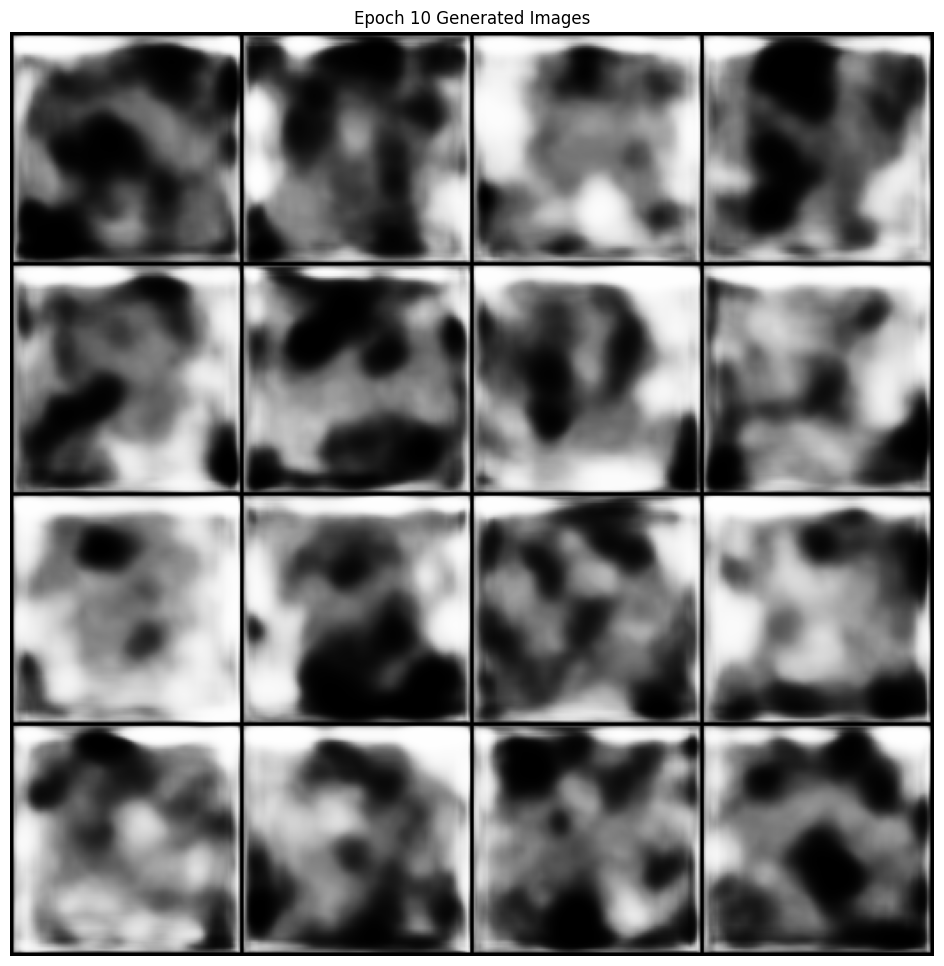

Epoch [11/200], Step [10/17], D Loss: 1.3346, G Loss: 0.7829, D(x): 0.50, D(G(z)): 0.47
Epoch [12/200], Step [10/17], D Loss: 1.3162, G Loss: 0.7548, D(x): 0.54, D(G(z)): 0.49
Epoch [13/200], Step [10/17], D Loss: 1.3079, G Loss: 0.7453, D(x): 0.48, D(G(z)): 0.42
Epoch [14/200], Step [10/17], D Loss: 1.2971, G Loss: 0.7471, D(x): 0.58, D(G(z)): 0.50
Epoch [15/200], Step [10/17], D Loss: 1.2756, G Loss: 0.7541, D(x): 0.51, D(G(z)): 0.43
Epoch [16/200], Step [10/17], D Loss: 1.2409, G Loss: 0.7998, D(x): 0.55, D(G(z)): 0.45
Epoch [17/200], Step [10/17], D Loss: 1.2133, G Loss: 0.8584, D(x): 0.56, D(G(z)): 0.43
Epoch [18/200], Step [10/17], D Loss: 1.1967, G Loss: 0.9261, D(x): 0.52, D(G(z)): 0.37
Epoch [19/200], Step [10/17], D Loss: 1.2576, G Loss: 0.9545, D(x): 0.67, D(G(z)): 0.55
Epoch [20/200], Step [10/17], D Loss: 1.1850, G Loss: 0.9875, D(x): 0.63, D(G(z)): 0.46
Best model saved at epoch 20 (G Loss: 0.9041)


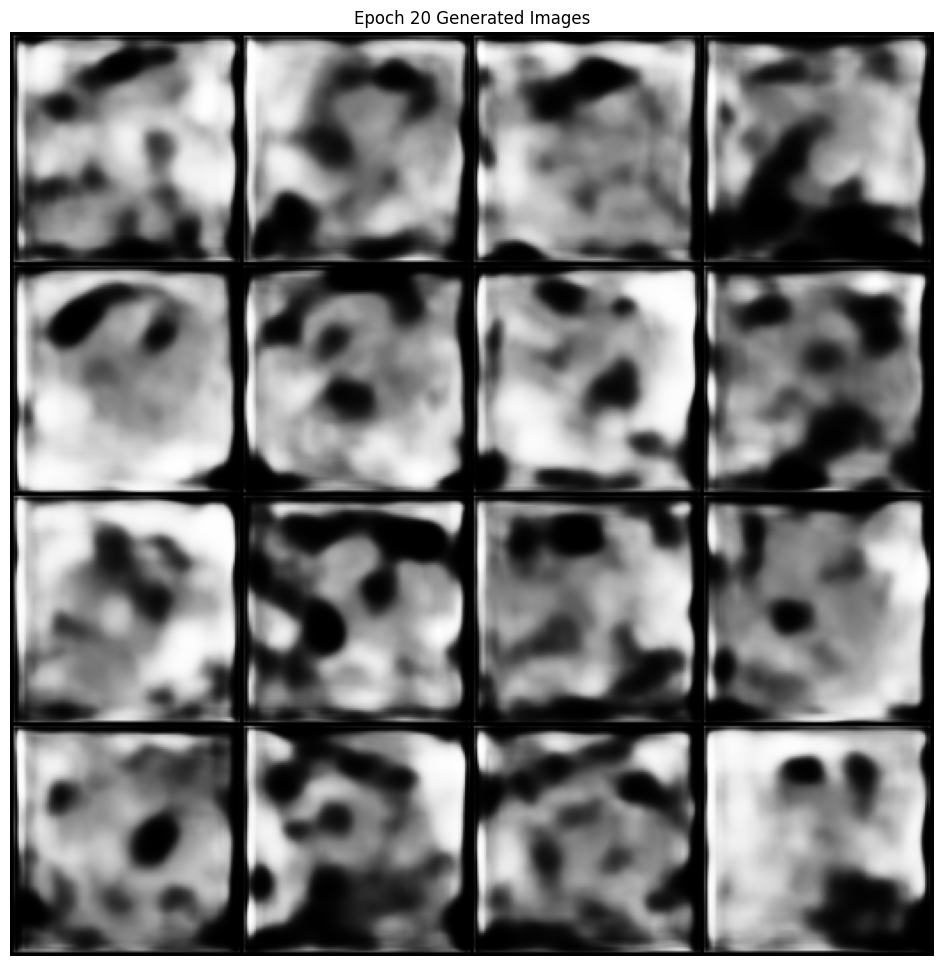

Epoch [21/200], Step [10/17], D Loss: 1.2309, G Loss: 1.1971, D(x): 0.71, D(G(z)): 0.55
Epoch [22/200], Step [10/17], D Loss: 1.2045, G Loss: 0.9371, D(x): 0.62, D(G(z)): 0.47
Epoch [23/200], Step [10/17], D Loss: 1.2964, G Loss: 1.2551, D(x): 0.76, D(G(z)): 0.59
Epoch [24/200], Step [10/17], D Loss: 1.2383, G Loss: 0.7801, D(x): 0.43, D(G(z)): 0.25
Epoch [25/200], Step [10/17], D Loss: 1.1592, G Loss: 1.0406, D(x): 0.58, D(G(z)): 0.39
Epoch [26/200], Step [10/17], D Loss: 1.1697, G Loss: 0.7396, D(x): 0.52, D(G(z)): 0.33
Epoch [27/200], Step [10/17], D Loss: 1.1492, G Loss: 0.6657, D(x): 0.54, D(G(z)): 0.35
Epoch [28/200], Step [10/17], D Loss: 1.1116, G Loss: 1.0171, D(x): 0.64, D(G(z)): 0.43
Epoch [29/200], Step [10/17], D Loss: 1.3678, G Loss: 0.6199, D(x): 0.37, D(G(z)): 0.21
Epoch [30/200], Step [10/17], D Loss: 1.2052, G Loss: 0.6595, D(x): 0.49, D(G(z)): 0.32
Best model saved at epoch 30 (G Loss: 0.9416)


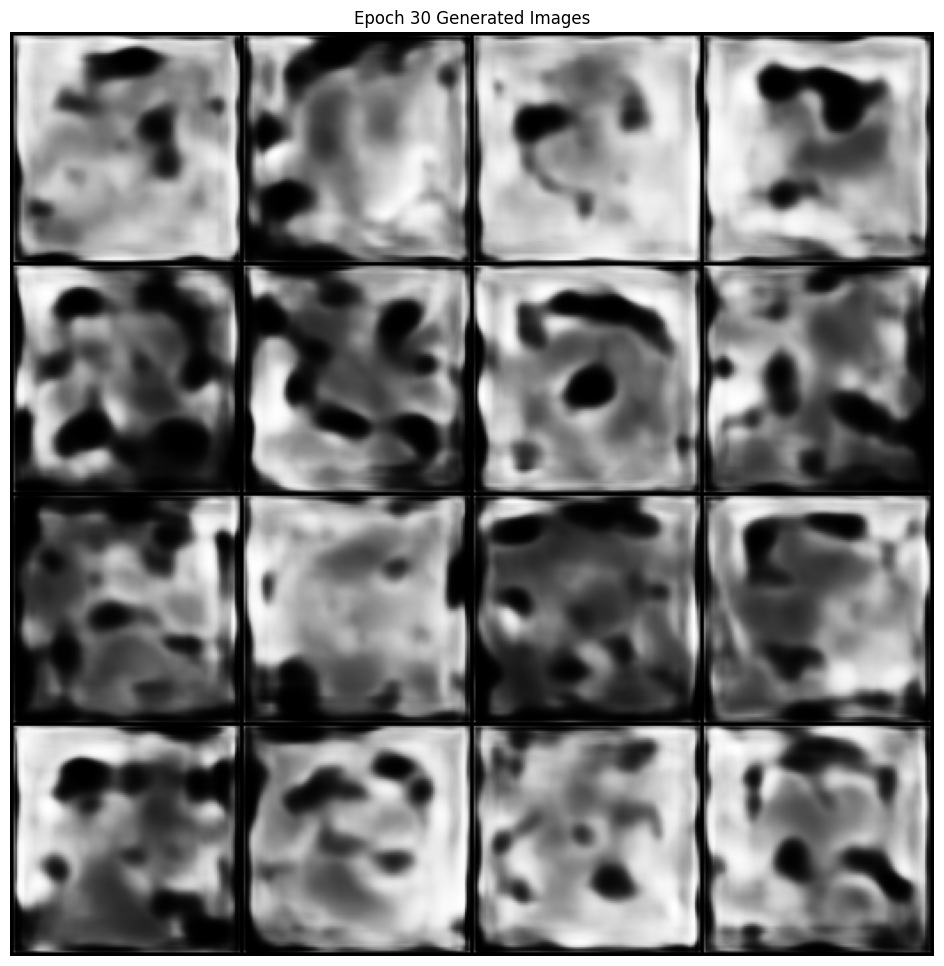

Epoch [31/200], Step [10/17], D Loss: 1.1144, G Loss: 0.9882, D(x): 0.62, D(G(z)): 0.40
Epoch [32/200], Step [10/17], D Loss: 1.1639, G Loss: 0.7091, D(x): 0.54, D(G(z)): 0.35
Epoch [33/200], Step [10/17], D Loss: 1.1262, G Loss: 0.9088, D(x): 0.61, D(G(z)): 0.40
Epoch [34/200], Step [10/17], D Loss: 1.2684, G Loss: 0.7189, D(x): 0.46, D(G(z)): 0.32
Epoch [35/200], Step [10/17], D Loss: 1.2544, G Loss: 0.8590, D(x): 0.54, D(G(z)): 0.41
Epoch [36/200], Step [10/17], D Loss: 1.2209, G Loss: 0.8610, D(x): 0.55, D(G(z)): 0.42
Epoch [37/200], Step [10/17], D Loss: 1.2232, G Loss: 0.7962, D(x): 0.56, D(G(z)): 0.42
Epoch [38/200], Step [10/17], D Loss: 1.1924, G Loss: 0.8733, D(x): 0.56, D(G(z)): 0.40
Epoch [39/200], Step [10/17], D Loss: 1.1985, G Loss: 0.8387, D(x): 0.58, D(G(z)): 0.41
Epoch [40/200], Step [10/17], D Loss: 1.2499, G Loss: 0.9482, D(x): 0.57, D(G(z)): 0.46
Best model saved at epoch 40 (G Loss: 0.8511)


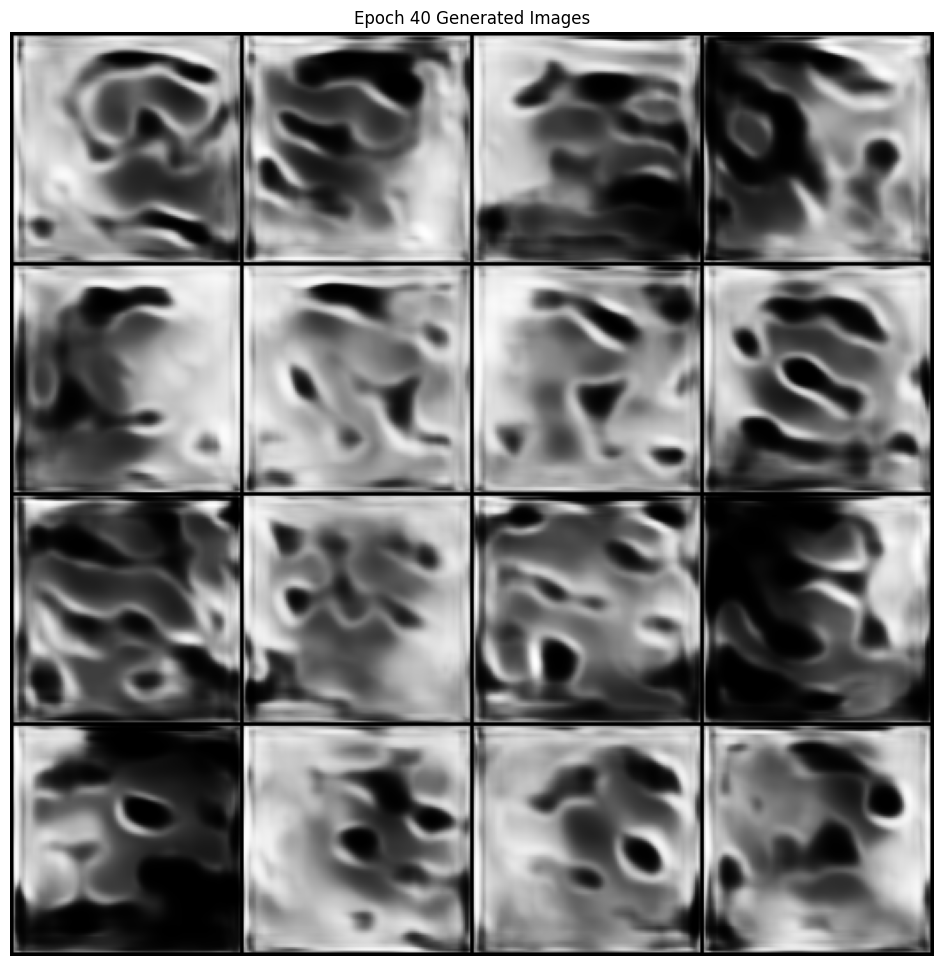

Epoch [41/200], Step [10/17], D Loss: 1.2377, G Loss: 0.9574, D(x): 0.63, D(G(z)): 0.49
Epoch [42/200], Step [10/17], D Loss: 1.2041, G Loss: 1.0122, D(x): 0.59, D(G(z)): 0.44
Epoch [43/200], Step [10/17], D Loss: 1.2196, G Loss: 0.8086, D(x): 0.55, D(G(z)): 0.42
Epoch [44/200], Step [10/17], D Loss: 1.3002, G Loss: 0.7852, D(x): 0.45, D(G(z)): 0.32
Epoch [45/200], Step [10/17], D Loss: 1.1884, G Loss: 0.9615, D(x): 0.63, D(G(z)): 0.46
Epoch [46/200], Step [10/17], D Loss: 1.2507, G Loss: 0.6472, D(x): 0.50, D(G(z)): 0.39
Epoch [47/200], Step [10/17], D Loss: 1.2314, G Loss: 0.6961, D(x): 0.58, D(G(z)): 0.45
Epoch [48/200], Step [10/17], D Loss: 1.2633, G Loss: 0.8984, D(x): 0.59, D(G(z)): 0.48
Epoch [49/200], Step [10/17], D Loss: 1.2134, G Loss: 0.9528, D(x): 0.60, D(G(z)): 0.46
Epoch [50/200], Step [10/17], D Loss: 1.2504, G Loss: 0.7220, D(x): 0.53, D(G(z)): 0.42
Best model saved at epoch 50 (G Loss: 0.8241)


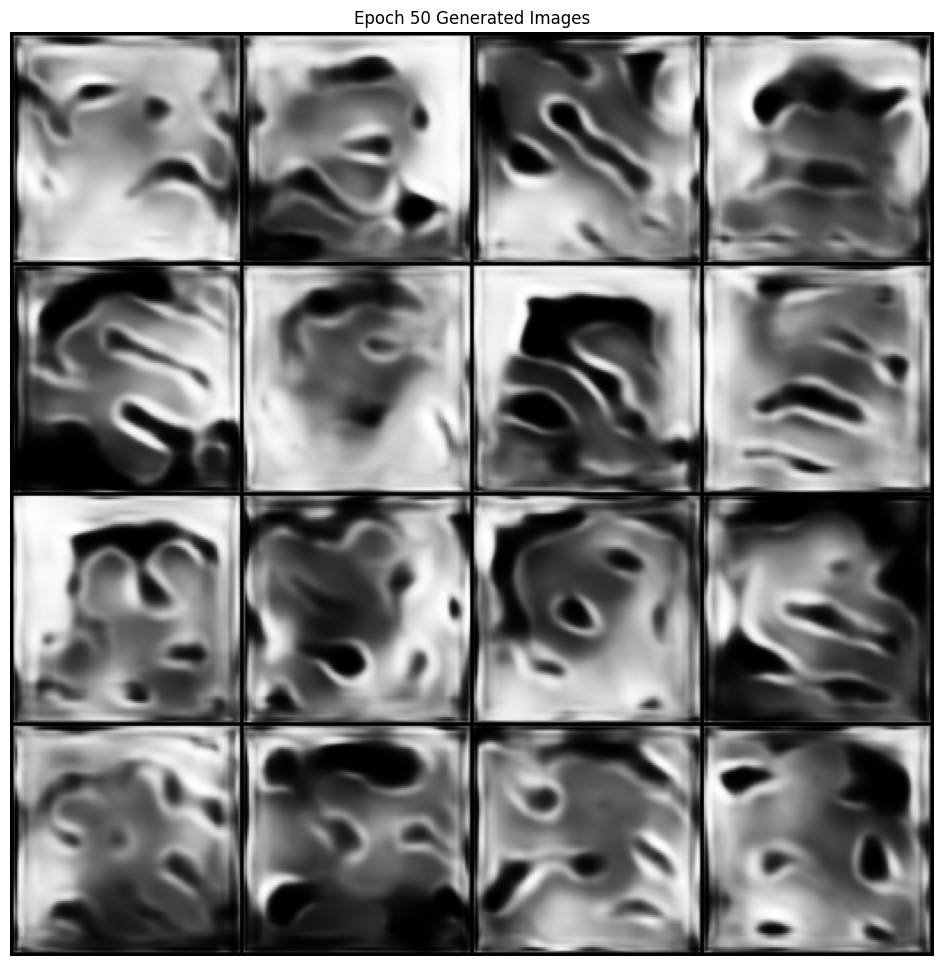

Epoch [51/200], Step [10/17], D Loss: 1.2689, G Loss: 0.7655, D(x): 0.55, D(G(z)): 0.45
Epoch [52/200], Step [10/17], D Loss: 1.3105, G Loss: 0.6470, D(x): 0.45, D(G(z)): 0.36
Epoch [53/200], Step [10/17], D Loss: 1.2981, G Loss: 1.0002, D(x): 0.66, D(G(z)): 0.56
Epoch [54/200], Step [10/17], D Loss: 1.2260, G Loss: 0.7725, D(x): 0.56, D(G(z)): 0.43
Epoch [55/200], Step [10/17], D Loss: 1.2651, G Loss: 0.6635, D(x): 0.49, D(G(z)): 0.38
Epoch [56/200], Step [10/17], D Loss: 1.2587, G Loss: 0.6920, D(x): 0.49, D(G(z)): 0.37
Epoch [57/200], Step [10/17], D Loss: 1.2211, G Loss: 0.8416, D(x): 0.53, D(G(z)): 0.40
Epoch [58/200], Step [10/17], D Loss: 1.2291, G Loss: 0.8782, D(x): 0.59, D(G(z)): 0.47
Epoch [59/200], Step [10/17], D Loss: 1.2719, G Loss: 0.8518, D(x): 0.58, D(G(z)): 0.48
Epoch [60/200], Step [10/17], D Loss: 1.2848, G Loss: 0.5781, D(x): 0.47, D(G(z)): 0.37
Best model saved at epoch 60 (G Loss: 0.8411)


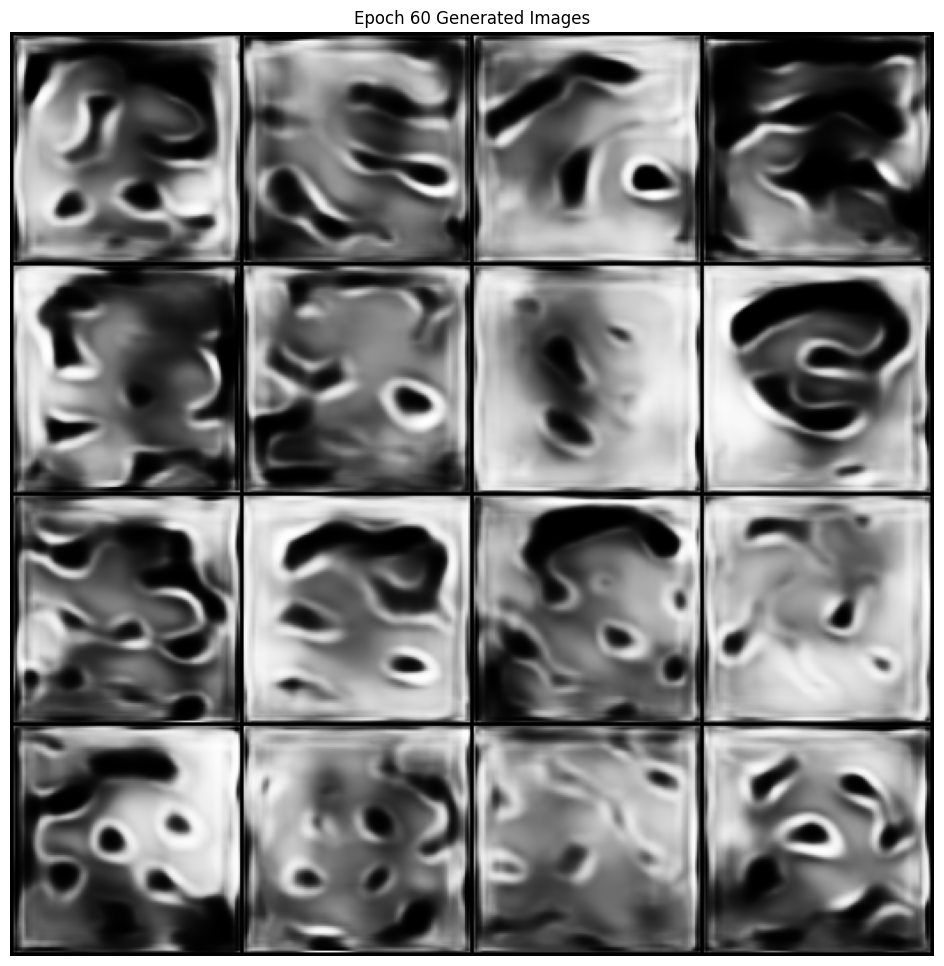

Epoch [61/200], Step [10/17], D Loss: 1.2449, G Loss: 0.7294, D(x): 0.50, D(G(z)): 0.38
Epoch [62/200], Step [10/17], D Loss: 1.2486, G Loss: 0.8307, D(x): 0.58, D(G(z)): 0.47
Epoch [63/200], Step [10/17], D Loss: 1.2615, G Loss: 0.9581, D(x): 0.62, D(G(z)): 0.50
Epoch [64/200], Step [10/17], D Loss: 1.2764, G Loss: 0.8656, D(x): 0.61, D(G(z)): 0.50
Epoch [65/200], Step [10/17], D Loss: 1.2924, G Loss: 0.8916, D(x): 0.56, D(G(z)): 0.48
Epoch [66/200], Step [10/17], D Loss: 1.2474, G Loss: 0.8081, D(x): 0.57, D(G(z)): 0.46
Epoch [67/200], Step [10/17], D Loss: 1.2416, G Loss: 0.7767, D(x): 0.52, D(G(z)): 0.39
Epoch [68/200], Step [10/17], D Loss: 1.2332, G Loss: 0.8379, D(x): 0.58, D(G(z)): 0.46
Epoch [69/200], Step [10/17], D Loss: 1.2454, G Loss: 0.7654, D(x): 0.57, D(G(z)): 0.46
Epoch [70/200], Step [10/17], D Loss: 1.2372, G Loss: 0.7233, D(x): 0.51, D(G(z)): 0.37
Best model saved at epoch 70 (G Loss: 0.8262)


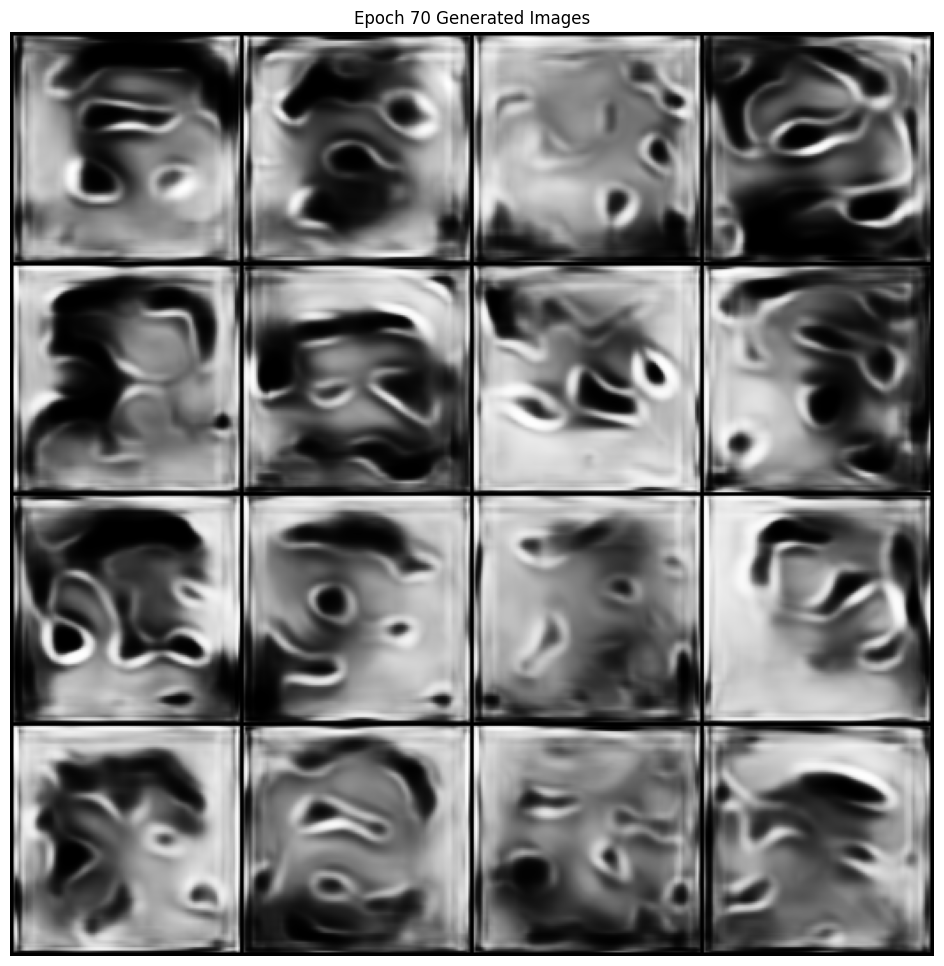

Epoch [71/200], Step [10/17], D Loss: 1.2384, G Loss: 0.8188, D(x): 0.55, D(G(z)): 0.43
Epoch [72/200], Step [10/17], D Loss: 1.2091, G Loss: 0.9393, D(x): 0.64, D(G(z)): 0.49
Epoch [73/200], Step [10/17], D Loss: 1.1913, G Loss: 0.7358, D(x): 0.56, D(G(z)): 0.42
Epoch [74/200], Step [10/17], D Loss: 1.2790, G Loss: 0.8288, D(x): 0.56, D(G(z)): 0.47
Epoch [75/200], Step [10/17], D Loss: 1.2397, G Loss: 0.6333, D(x): 0.49, D(G(z)): 0.35
Epoch [76/200], Step [10/17], D Loss: 1.2531, G Loss: 1.0086, D(x): 0.63, D(G(z)): 0.49
Epoch [77/200], Step [10/17], D Loss: 1.2478, G Loss: 0.7767, D(x): 0.49, D(G(z)): 0.36
Epoch [78/200], Step [10/17], D Loss: 1.1972, G Loss: 0.7576, D(x): 0.53, D(G(z)): 0.36
Epoch [79/200], Step [10/17], D Loss: 1.2312, G Loss: 0.9085, D(x): 0.68, D(G(z)): 0.52
Epoch [80/200], Step [10/17], D Loss: 1.2322, G Loss: 0.8287, D(x): 0.53, D(G(z)): 0.41
Best model saved at epoch 80 (G Loss: 0.8818)


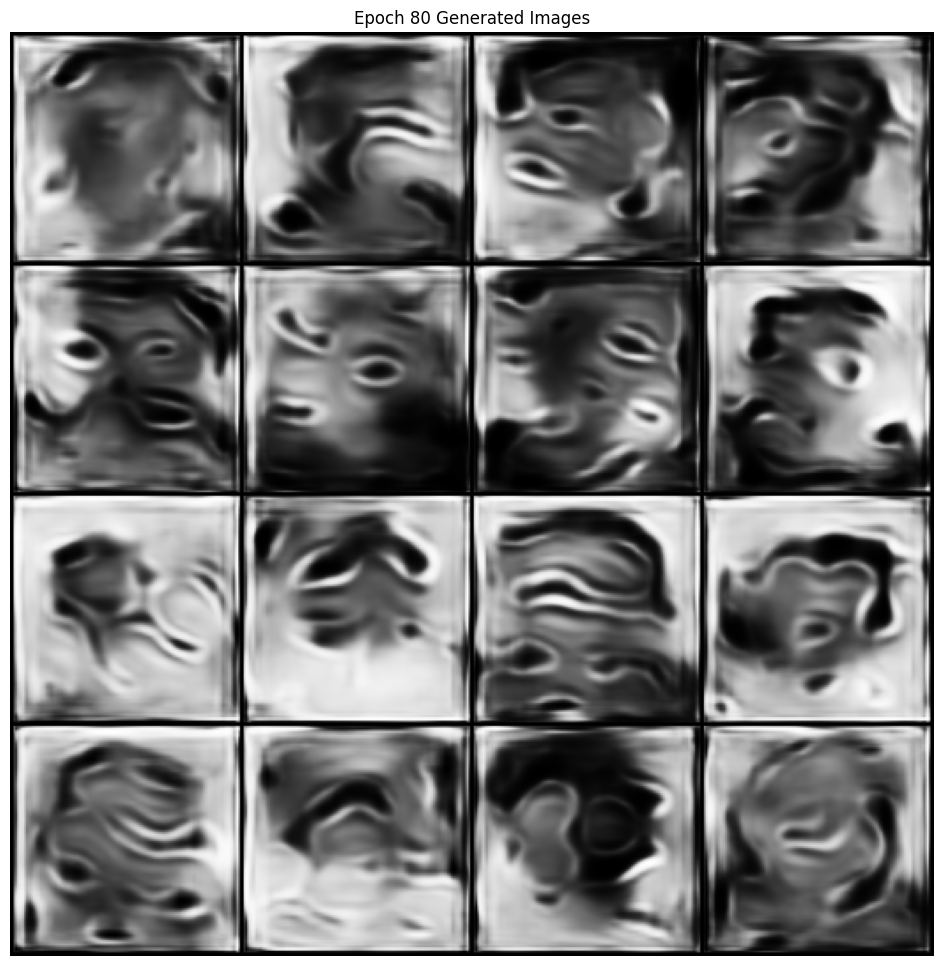

Epoch [81/200], Step [10/17], D Loss: 1.2685, G Loss: 0.9861, D(x): 0.63, D(G(z)): 0.51
Epoch [82/200], Step [10/17], D Loss: 1.1928, G Loss: 0.7688, D(x): 0.57, D(G(z)): 0.41
Epoch [83/200], Step [10/17], D Loss: 1.1901, G Loss: 0.9346, D(x): 0.64, D(G(z)): 0.47
Epoch [84/200], Step [10/17], D Loss: 1.4739, G Loss: 0.6335, D(x): 0.37, D(G(z)): 0.30
Epoch [85/200], Step [10/17], D Loss: 1.2083, G Loss: 0.8658, D(x): 0.55, D(G(z)): 0.40
Epoch [86/200], Step [10/17], D Loss: 1.1724, G Loss: 0.8671, D(x): 0.54, D(G(z)): 0.37
Epoch [87/200], Step [10/17], D Loss: 1.1511, G Loss: 1.1221, D(x): 0.55, D(G(z)): 0.35
Epoch [88/200], Step [10/17], D Loss: 1.1514, G Loss: 0.9039, D(x): 0.58, D(G(z)): 0.39
Epoch [89/200], Step [10/17], D Loss: 1.1501, G Loss: 0.7456, D(x): 0.56, D(G(z)): 0.37
Epoch [90/200], Step [10/17], D Loss: 1.1887, G Loss: 0.8188, D(x): 0.54, D(G(z)): 0.37
Best model saved at epoch 90 (G Loss: 0.9649)


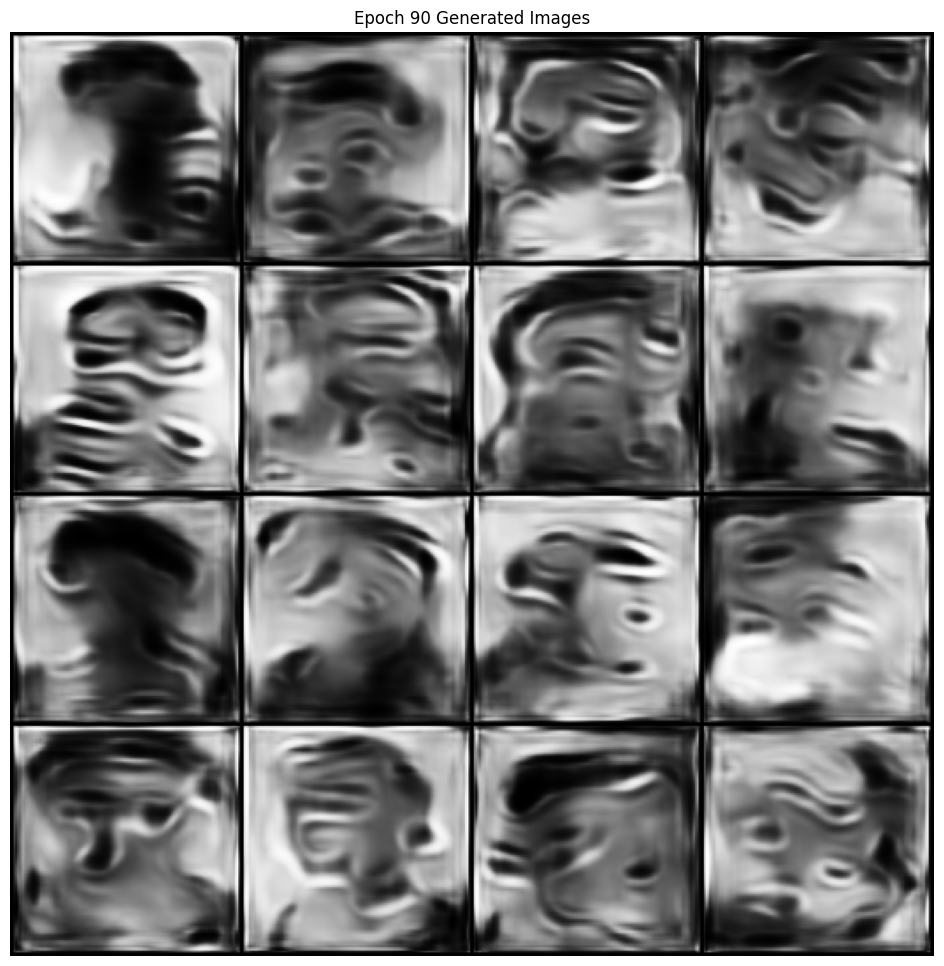

Epoch [91/200], Step [10/17], D Loss: 1.1415, G Loss: 0.9005, D(x): 0.56, D(G(z)): 0.35
Epoch [92/200], Step [10/17], D Loss: 1.1512, G Loss: 0.9536, D(x): 0.58, D(G(z)): 0.38
Epoch [93/200], Step [10/17], D Loss: 1.1311, G Loss: 0.7898, D(x): 0.52, D(G(z)): 0.29
Epoch [94/200], Step [10/17], D Loss: 1.1380, G Loss: 0.8040, D(x): 0.59, D(G(z)): 0.39
Epoch [95/200], Step [10/17], D Loss: 1.0637, G Loss: 0.8823, D(x): 0.61, D(G(z)): 0.35
Epoch [96/200], Step [10/17], D Loss: 1.1930, G Loss: 1.1935, D(x): 0.72, D(G(z)): 0.52
Epoch [97/200], Step [10/17], D Loss: 1.1508, G Loss: 1.1618, D(x): 0.62, D(G(z)): 0.42
Epoch [98/200], Step [10/17], D Loss: 1.1484, G Loss: 0.6784, D(x): 0.52, D(G(z)): 0.29
Epoch [99/200], Step [10/17], D Loss: 1.0503, G Loss: 0.8699, D(x): 0.63, D(G(z)): 0.35
Epoch [100/200], Step [10/17], D Loss: 1.0848, G Loss: 1.0542, D(x): 0.65, D(G(z)): 0.40
Best model saved at epoch 100 (G Loss: 1.0216)


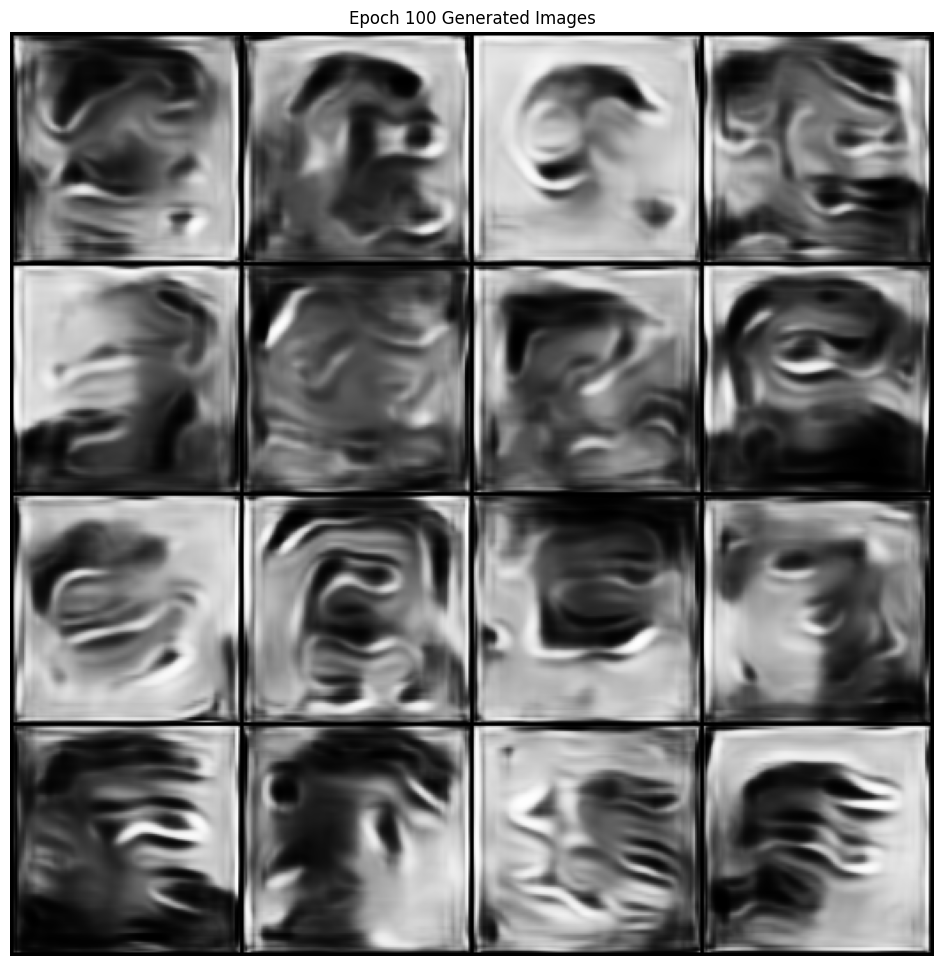

Epoch [101/200], Step [10/17], D Loss: 1.0832, G Loss: 0.9396, D(x): 0.55, D(G(z)): 0.29
Epoch [102/200], Step [10/17], D Loss: 1.0524, G Loss: 1.1409, D(x): 0.65, D(G(z)): 0.38
Epoch [103/200], Step [10/17], D Loss: 1.0987, G Loss: 0.7145, D(x): 0.54, D(G(z)): 0.26
Epoch [104/200], Step [10/17], D Loss: 1.2901, G Loss: 1.0778, D(x): 0.79, D(G(z)): 0.57
Epoch [105/200], Step [10/17], D Loss: 1.0719, G Loss: 0.8037, D(x): 0.60, D(G(z)): 0.33
Epoch [106/200], Step [10/17], D Loss: 1.1684, G Loss: 1.4891, D(x): 0.72, D(G(z)): 0.49
Epoch [107/200], Step [10/17], D Loss: 1.1002, G Loss: 1.0786, D(x): 0.64, D(G(z)): 0.40
Epoch [108/200], Step [10/17], D Loss: 1.0345, G Loss: 1.1076, D(x): 0.68, D(G(z)): 0.36
Epoch [109/200], Step [10/17], D Loss: 1.0448, G Loss: 1.0617, D(x): 0.62, D(G(z)): 0.32
Epoch [110/200], Step [10/17], D Loss: 1.0186, G Loss: 1.0409, D(x): 0.65, D(G(z)): 0.34
Best model saved at epoch 110 (G Loss: 1.1423)


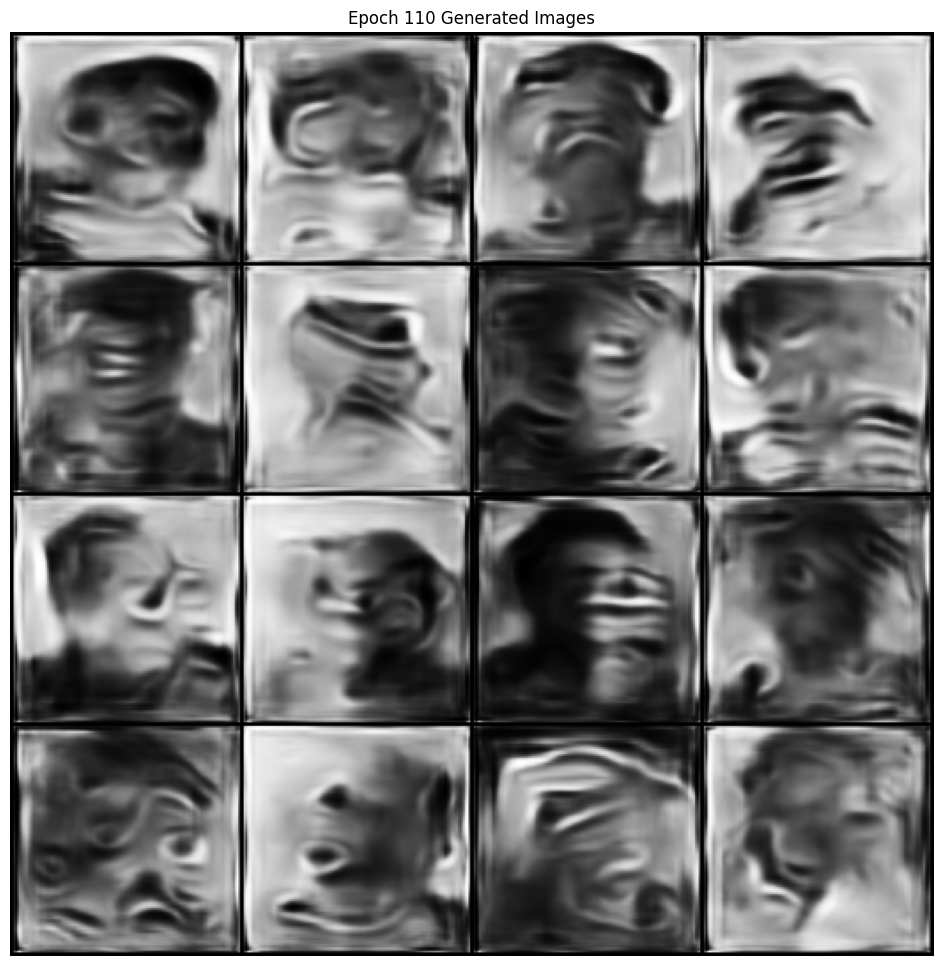

Epoch [111/200], Step [10/17], D Loss: 1.0049, G Loss: 1.0272, D(x): 0.62, D(G(z)): 0.28
Epoch [112/200], Step [10/17], D Loss: 1.0453, G Loss: 1.0816, D(x): 0.75, D(G(z)): 0.44
Epoch [113/200], Step [10/17], D Loss: 1.0595, G Loss: 0.8967, D(x): 0.60, D(G(z)): 0.29
Epoch [114/200], Step [10/17], D Loss: 1.1957, G Loss: 1.3972, D(x): 0.82, D(G(z)): 0.54
Epoch [115/200], Step [10/17], D Loss: 1.0392, G Loss: 1.4106, D(x): 0.76, D(G(z)): 0.44
Epoch [116/200], Step [10/17], D Loss: 1.0993, G Loss: 0.7779, D(x): 0.50, D(G(z)): 0.18
Epoch [117/200], Step [10/17], D Loss: 1.0981, G Loss: 0.7632, D(x): 0.53, D(G(z)): 0.25
Epoch [118/200], Step [10/17], D Loss: 0.9861, G Loss: 1.3187, D(x): 0.76, D(G(z)): 0.39
Epoch [119/200], Step [10/17], D Loss: 1.0149, G Loss: 1.2387, D(x): 0.69, D(G(z)): 0.36
Epoch [120/200], Step [10/17], D Loss: 1.0019, G Loss: 1.3393, D(x): 0.68, D(G(z)): 0.33
Best model saved at epoch 120 (G Loss: 1.1710)


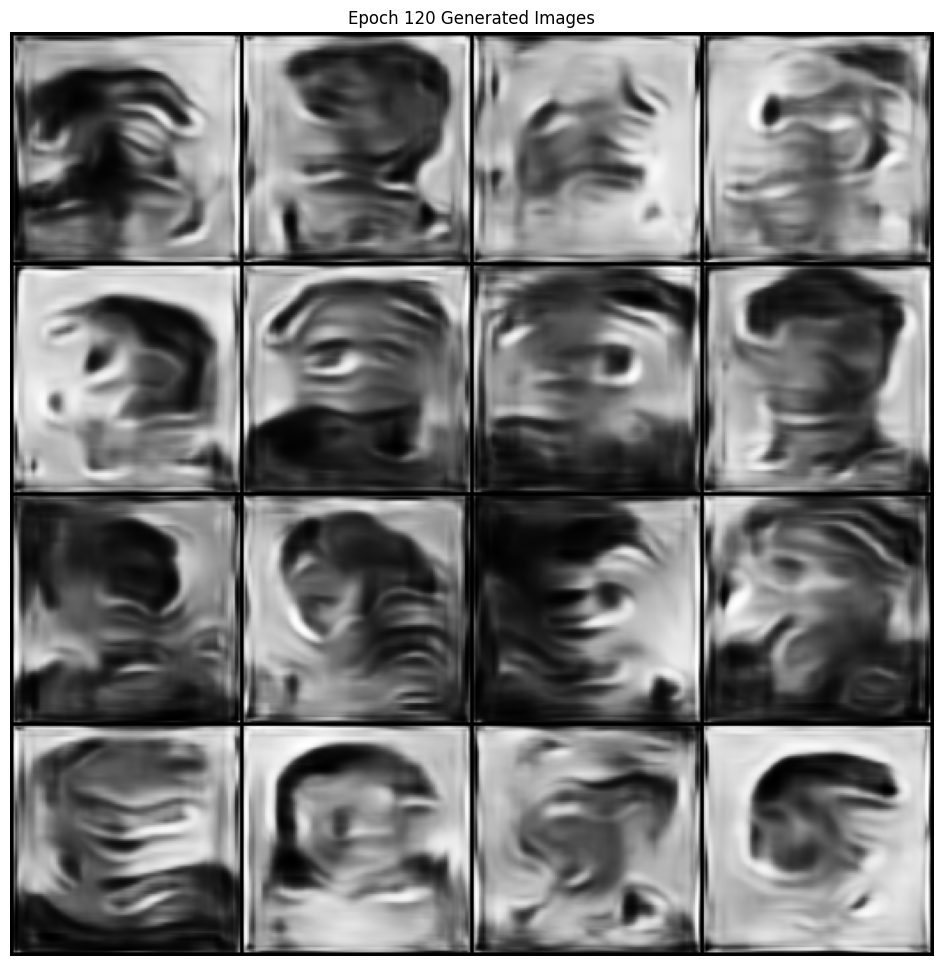

Epoch [121/200], Step [10/17], D Loss: 1.1319, G Loss: 1.0418, D(x): 0.51, D(G(z)): 0.22
Epoch [122/200], Step [10/17], D Loss: 0.9963, G Loss: 0.9639, D(x): 0.65, D(G(z)): 0.31
Epoch [123/200], Step [10/17], D Loss: 1.0460, G Loss: 1.0378, D(x): 0.65, D(G(z)): 0.35
Epoch [124/200], Step [10/17], D Loss: 0.9582, G Loss: 1.1692, D(x): 0.76, D(G(z)): 0.38
Epoch [125/200], Step [10/17], D Loss: 0.9795, G Loss: 1.2630, D(x): 0.71, D(G(z)): 0.35
Epoch [126/200], Step [10/17], D Loss: 0.9874, G Loss: 1.0426, D(x): 0.65, D(G(z)): 0.30
Epoch [127/200], Step [10/17], D Loss: 0.9579, G Loss: 1.1614, D(x): 0.66, D(G(z)): 0.28
Epoch [128/200], Step [10/17], D Loss: 1.0050, G Loss: 0.8326, D(x): 0.60, D(G(z)): 0.24
Epoch [129/200], Step [10/17], D Loss: 0.9645, G Loss: 0.9510, D(x): 0.66, D(G(z)): 0.29
Epoch [130/200], Step [10/17], D Loss: 1.0584, G Loss: 0.6507, D(x): 0.53, D(G(z)): 0.17
Best model saved at epoch 130 (G Loss: 1.3008)


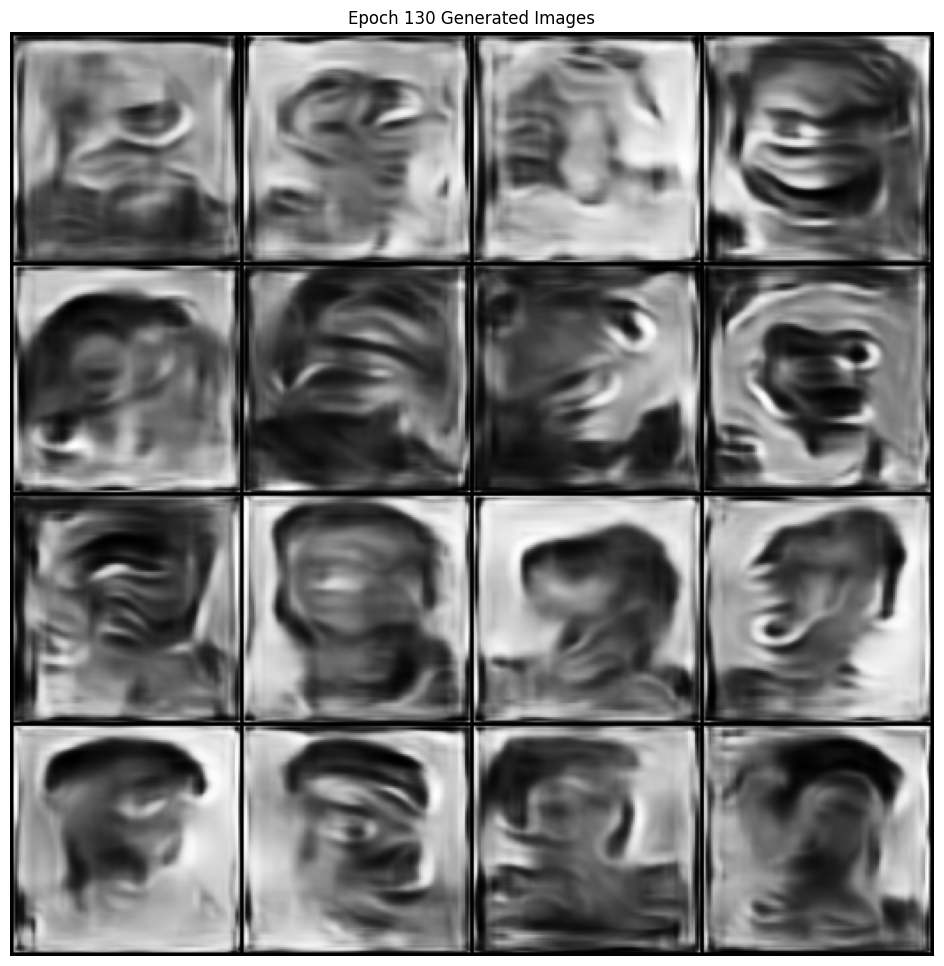

Epoch [131/200], Step [10/17], D Loss: 0.9459, G Loss: 1.3051, D(x): 0.73, D(G(z)): 0.33
Epoch [132/200], Step [10/17], D Loss: 0.9736, G Loss: 1.3122, D(x): 0.62, D(G(z)): 0.24
Epoch [133/200], Step [10/17], D Loss: 0.9532, G Loss: 1.1778, D(x): 0.72, D(G(z)): 0.34
Epoch [134/200], Step [10/17], D Loss: 0.9959, G Loss: 1.0217, D(x): 0.58, D(G(z)): 0.19
Epoch [135/200], Step [10/17], D Loss: 0.9447, G Loss: 1.5585, D(x): 0.75, D(G(z)): 0.34
Epoch [136/200], Step [10/17], D Loss: 0.9425, G Loss: 0.9941, D(x): 0.63, D(G(z)): 0.21
Epoch [137/200], Step [10/17], D Loss: 1.0553, G Loss: 0.8895, D(x): 0.55, D(G(z)): 0.16
Epoch [138/200], Step [10/17], D Loss: 0.9483, G Loss: 0.9754, D(x): 0.64, D(G(z)): 0.23
Epoch [139/200], Step [10/17], D Loss: 1.1362, G Loss: 1.3845, D(x): 0.87, D(G(z)): 0.52
Epoch [140/200], Step [10/17], D Loss: 0.9627, G Loss: 1.7340, D(x): 0.80, D(G(z)): 0.38
Best model saved at epoch 140 (G Loss: 1.3492)


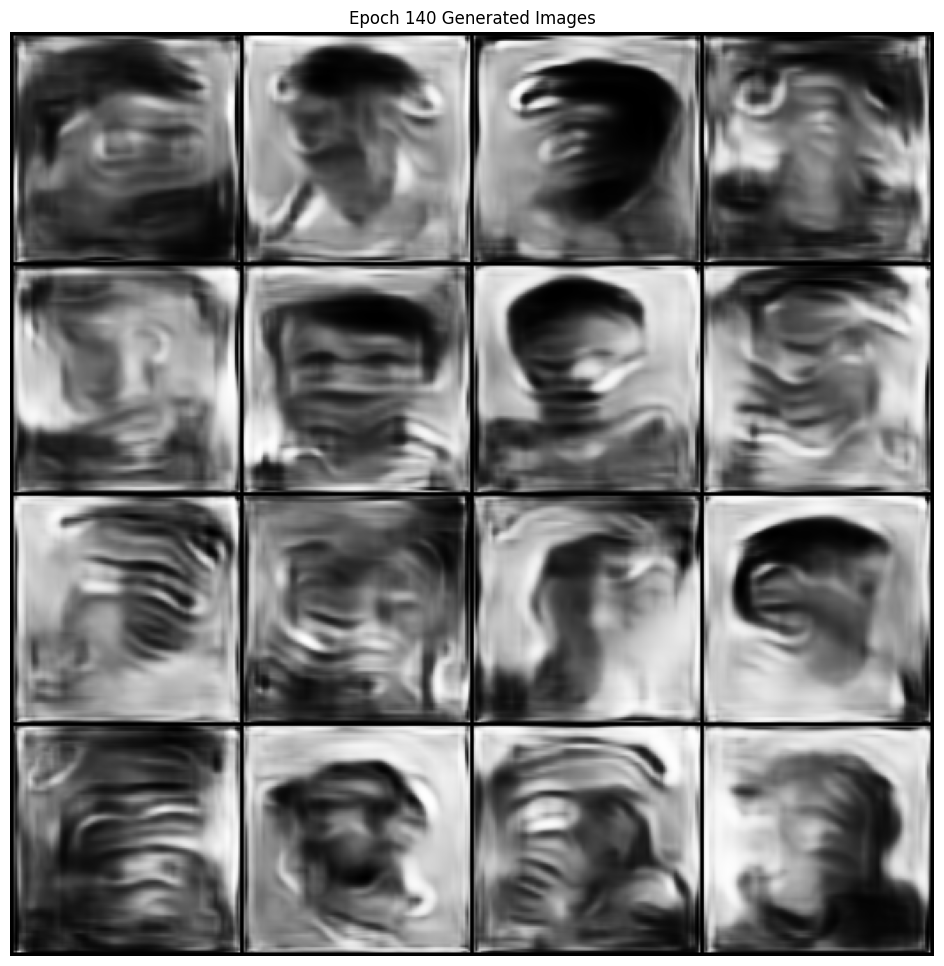

Epoch [141/200], Step [10/17], D Loss: 1.3552, G Loss: 1.5377, D(x): 0.93, D(G(z)): 0.60
Epoch [142/200], Step [10/17], D Loss: 0.8879, G Loss: 1.1980, D(x): 0.73, D(G(z)): 0.29
Epoch [143/200], Step [10/17], D Loss: 0.9135, G Loss: 1.4067, D(x): 0.78, D(G(z)): 0.34
Epoch [144/200], Step [10/17], D Loss: 0.9095, G Loss: 1.4710, D(x): 0.76, D(G(z)): 0.33
Epoch [145/200], Step [10/17], D Loss: 0.8671, G Loss: 1.1558, D(x): 0.70, D(G(z)): 0.19
Epoch [146/200], Step [10/17], D Loss: 1.0583, G Loss: 1.8516, D(x): 0.90, D(G(z)): 0.46
Epoch [147/200], Step [10/17], D Loss: 0.9187, G Loss: 1.3527, D(x): 0.67, D(G(z)): 0.21
Epoch [148/200], Step [10/17], D Loss: 0.9075, G Loss: 1.7212, D(x): 0.81, D(G(z)): 0.35
Epoch [149/200], Step [10/17], D Loss: 0.9066, G Loss: 1.3997, D(x): 0.66, D(G(z)): 0.19
Epoch [150/200], Step [10/17], D Loss: 0.9006, G Loss: 0.9862, D(x): 0.68, D(G(z)): 0.22
Best model saved at epoch 150 (G Loss: 1.3998)


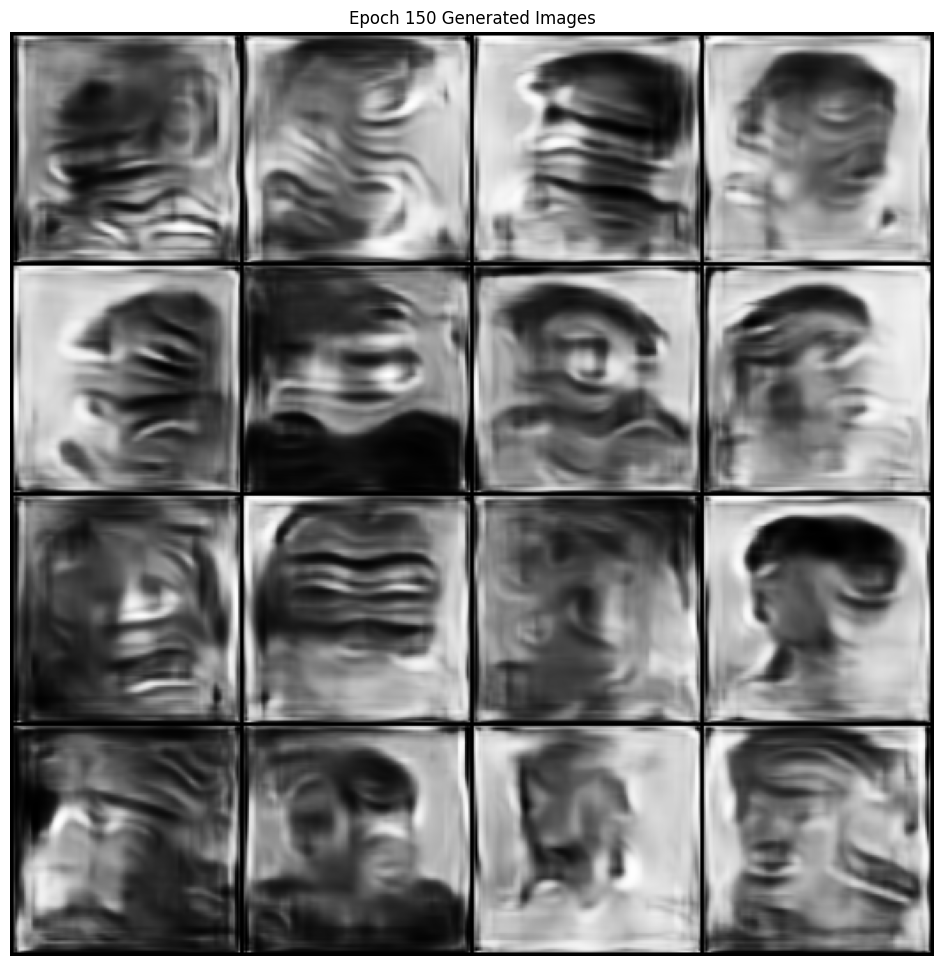

Epoch [151/200], Step [10/17], D Loss: 0.9803, G Loss: 1.8135, D(x): 0.85, D(G(z)): 0.42
Epoch [152/200], Step [10/17], D Loss: 0.9104, G Loss: 1.1821, D(x): 0.84, D(G(z)): 0.35
Epoch [153/200], Step [10/17], D Loss: 0.8477, G Loss: 1.3834, D(x): 0.73, D(G(z)): 0.21
Epoch [154/200], Step [10/17], D Loss: 1.0818, G Loss: 1.3004, D(x): 0.83, D(G(z)): 0.44
Epoch [155/200], Step [10/17], D Loss: 0.8931, G Loss: 1.2464, D(x): 0.70, D(G(z)): 0.23
Epoch [156/200], Step [10/17], D Loss: 0.8641, G Loss: 1.6638, D(x): 0.82, D(G(z)): 0.31
Epoch [157/200], Step [10/17], D Loss: 0.8543, G Loss: 1.2049, D(x): 0.73, D(G(z)): 0.23
Epoch [158/200], Step [10/17], D Loss: 0.8944, G Loss: 1.3093, D(x): 0.69, D(G(z)): 0.21
Epoch [159/200], Step [10/17], D Loss: 0.8434, G Loss: 1.4360, D(x): 0.76, D(G(z)): 0.24
Epoch [160/200], Step [10/17], D Loss: 0.8845, G Loss: 1.8753, D(x): 0.83, D(G(z)): 0.34
Best model saved at epoch 160 (G Loss: 1.5236)


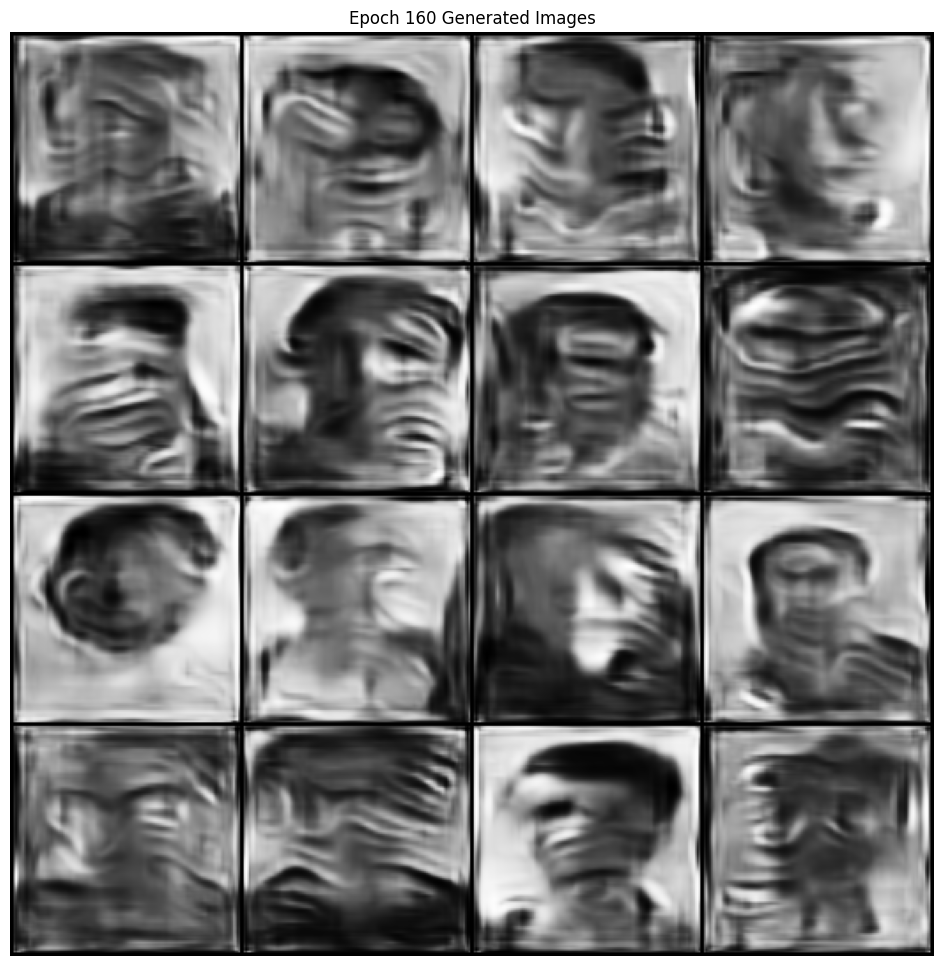

Epoch [161/200], Step [10/17], D Loss: 0.8863, G Loss: 1.3695, D(x): 0.69, D(G(z)): 0.19
Epoch [162/200], Step [10/17], D Loss: 0.8789, G Loss: 1.8308, D(x): 0.73, D(G(z)): 0.27
Epoch [163/200], Step [10/17], D Loss: 0.8577, G Loss: 1.5742, D(x): 0.82, D(G(z)): 0.29
Epoch [164/200], Step [10/17], D Loss: 1.1820, G Loss: 1.7968, D(x): 0.91, D(G(z)): 0.50
Epoch [165/200], Step [10/17], D Loss: 0.9022, G Loss: 1.0340, D(x): 0.67, D(G(z)): 0.19
Epoch [166/200], Step [10/17], D Loss: 0.8360, G Loss: 1.5436, D(x): 0.78, D(G(z)): 0.24
Epoch [167/200], Step [10/17], D Loss: 0.8543, G Loss: 2.0578, D(x): 0.78, D(G(z)): 0.27
Epoch [168/200], Step [10/17], D Loss: 0.8538, G Loss: 1.3108, D(x): 0.71, D(G(z)): 0.19
Epoch [169/200], Step [10/17], D Loss: 0.9128, G Loss: 1.3549, D(x): 0.78, D(G(z)): 0.31
Epoch [170/200], Step [10/17], D Loss: 0.8452, G Loss: 1.5391, D(x): 0.73, D(G(z)): 0.21
Best model saved at epoch 170 (G Loss: 1.5686)


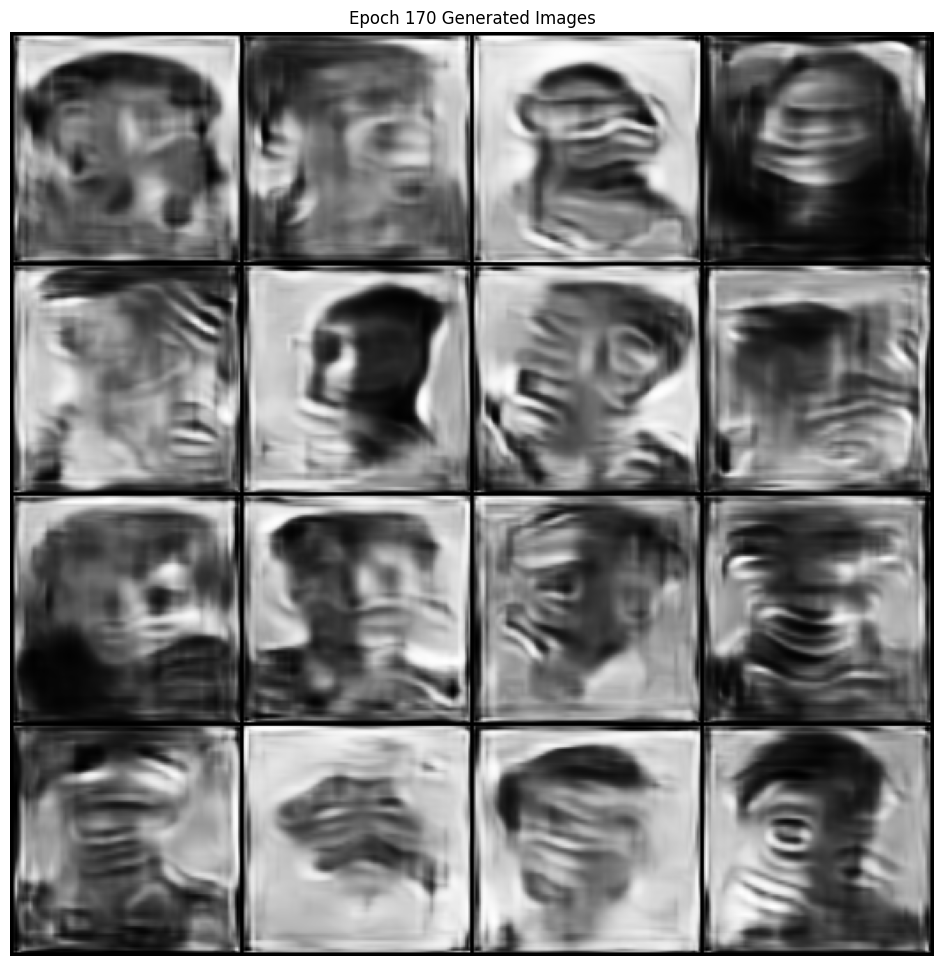

Epoch [171/200], Step [10/17], D Loss: 0.8866, G Loss: 0.9304, D(x): 0.65, D(G(z)): 0.15
Epoch [172/200], Step [10/17], D Loss: 0.8662, G Loss: 1.2974, D(x): 0.69, D(G(z)): 0.20
Epoch [173/200], Step [10/17], D Loss: 0.9869, G Loss: 2.0872, D(x): 0.89, D(G(z)): 0.41
Epoch [174/200], Step [10/17], D Loss: 0.9744, G Loss: 1.7016, D(x): 0.84, D(G(z)): 0.39
Epoch [175/200], Step [10/17], D Loss: 0.8365, G Loss: 1.2942, D(x): 0.74, D(G(z)): 0.20
Epoch [176/200], Step [10/17], D Loss: 0.8504, G Loss: 1.1883, D(x): 0.70, D(G(z)): 0.17
Epoch [177/200], Step [10/17], D Loss: 0.8201, G Loss: 1.3426, D(x): 0.81, D(G(z)): 0.26
Epoch [178/200], Step [10/17], D Loss: 1.3364, G Loss: 2.1268, D(x): 0.94, D(G(z)): 0.56
Epoch [179/200], Step [10/17], D Loss: 0.8378, G Loss: 1.2271, D(x): 0.71, D(G(z)): 0.17
Epoch [180/200], Step [10/17], D Loss: 0.8745, G Loss: 1.3092, D(x): 0.69, D(G(z)): 0.18
Best model saved at epoch 180 (G Loss: 1.6249)


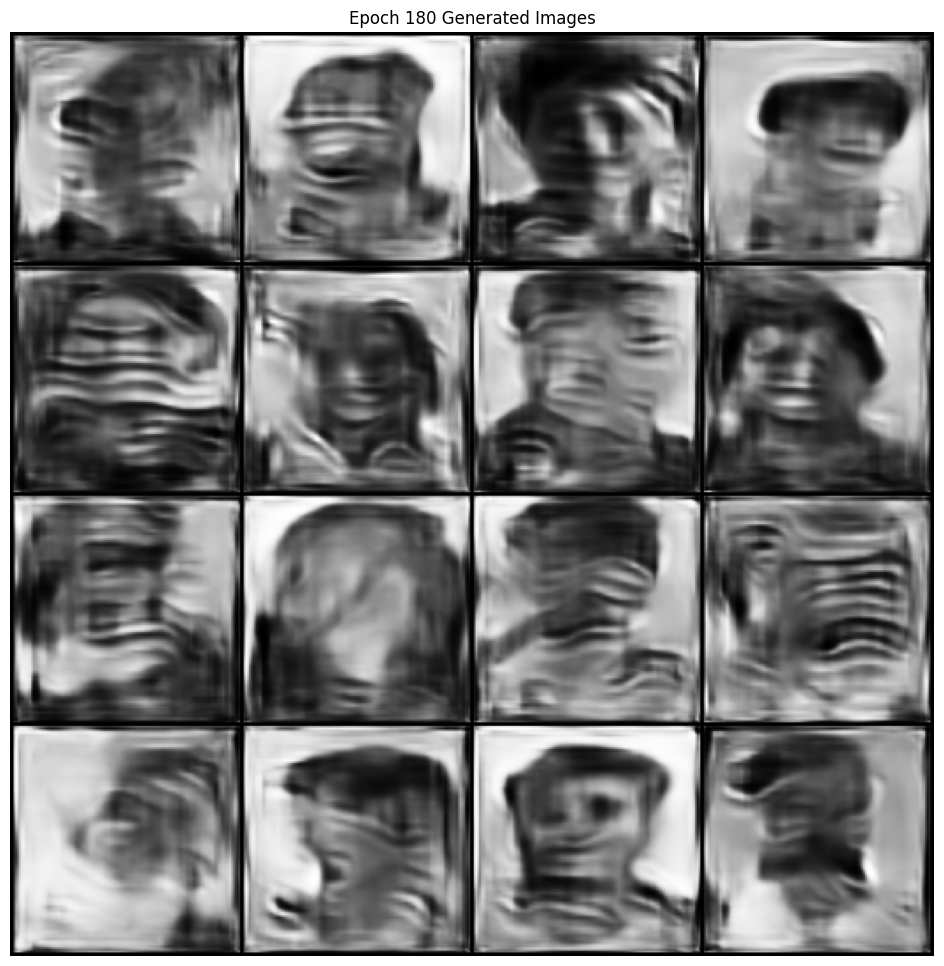

Epoch [181/200], Step [10/17], D Loss: 0.9156, G Loss: 1.5519, D(x): 0.67, D(G(z)): 0.17
Epoch [182/200], Step [10/17], D Loss: 0.8384, G Loss: 1.9591, D(x): 0.85, D(G(z)): 0.30
Epoch [183/200], Step [10/17], D Loss: 0.8515, G Loss: 2.0065, D(x): 0.83, D(G(z)): 0.29
Epoch [184/200], Step [10/17], D Loss: 0.8201, G Loss: 1.6686, D(x): 0.78, D(G(z)): 0.22
Epoch [185/200], Step [10/17], D Loss: 0.8009, G Loss: 1.4928, D(x): 0.75, D(G(z)): 0.18
Epoch [186/200], Step [10/17], D Loss: 0.8048, G Loss: 1.4784, D(x): 0.77, D(G(z)): 0.20
Epoch [187/200], Step [10/17], D Loss: 0.7920, G Loss: 1.6499, D(x): 0.77, D(G(z)): 0.19
Epoch [188/200], Step [10/17], D Loss: 1.1867, G Loss: 2.1511, D(x): 0.94, D(G(z)): 0.51
Epoch [189/200], Step [10/17], D Loss: 0.9169, G Loss: 1.3565, D(x): 0.64, D(G(z)): 0.13
Epoch [190/200], Step [10/17], D Loss: 0.8211, G Loss: 1.3557, D(x): 0.72, D(G(z)): 0.15
Best model saved at epoch 190 (G Loss: 1.6776)


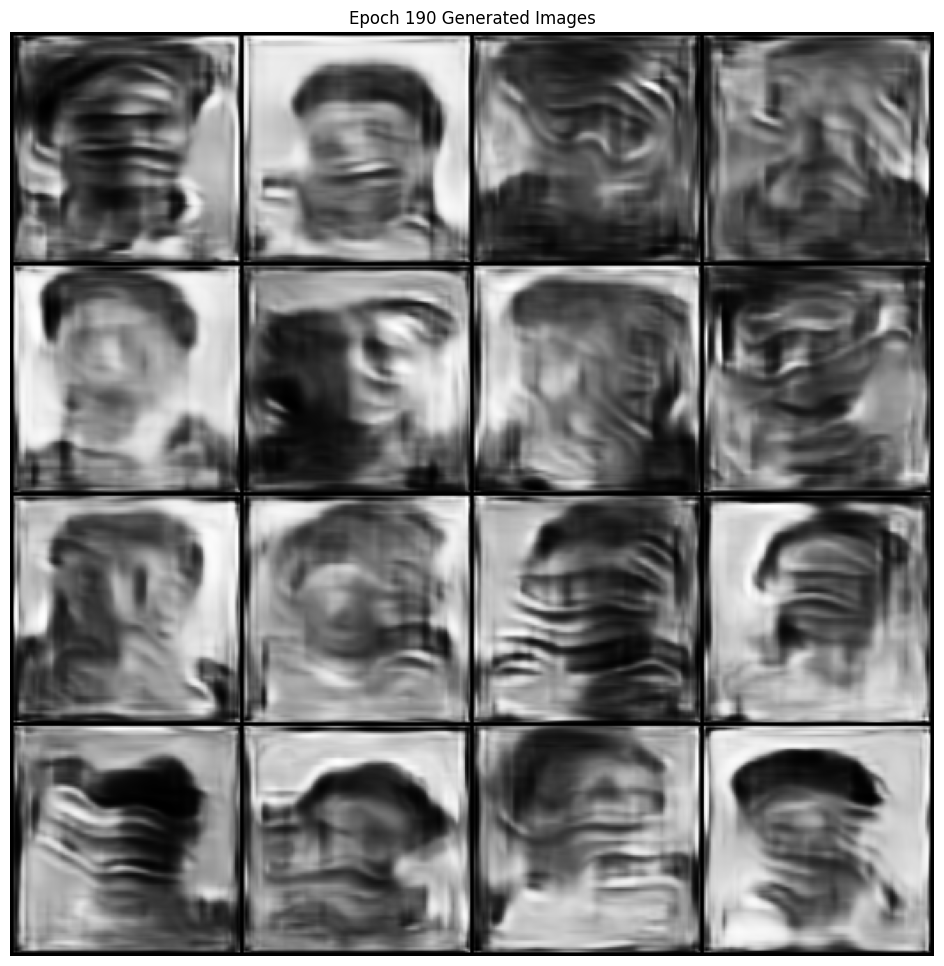

Epoch [191/200], Step [10/17], D Loss: 0.8966, G Loss: 1.7201, D(x): 0.81, D(G(z)): 0.32
Epoch [192/200], Step [10/17], D Loss: 0.8993, G Loss: 2.0132, D(x): 0.85, D(G(z)): 0.33
Epoch [193/200], Step [10/17], D Loss: 0.7753, G Loss: 1.5076, D(x): 0.81, D(G(z)): 0.22
Epoch [194/200], Step [10/17], D Loss: 0.8605, G Loss: 1.4463, D(x): 0.67, D(G(z)): 0.11
Epoch [195/200], Step [10/17], D Loss: 0.8974, G Loss: 0.9772, D(x): 0.65, D(G(z)): 0.12
Epoch [196/200], Step [10/17], D Loss: 0.8582, G Loss: 1.6951, D(x): 0.69, D(G(z)): 0.15
Epoch [197/200], Step [10/17], D Loss: 0.8012, G Loss: 1.9646, D(x): 0.83, D(G(z)): 0.24
Epoch [198/200], Step [10/17], D Loss: 0.8523, G Loss: 2.1202, D(x): 0.89, D(G(z)): 0.29
Epoch [199/200], Step [10/17], D Loss: 1.3910, G Loss: 1.9011, D(x): 0.94, D(G(z)): 0.58
Epoch [200/200], Step [10/17], D Loss: 0.7886, G Loss: 1.6561, D(x): 0.80, D(G(z)): 0.22
Best model saved at epoch 200 (G Loss: 1.7256)


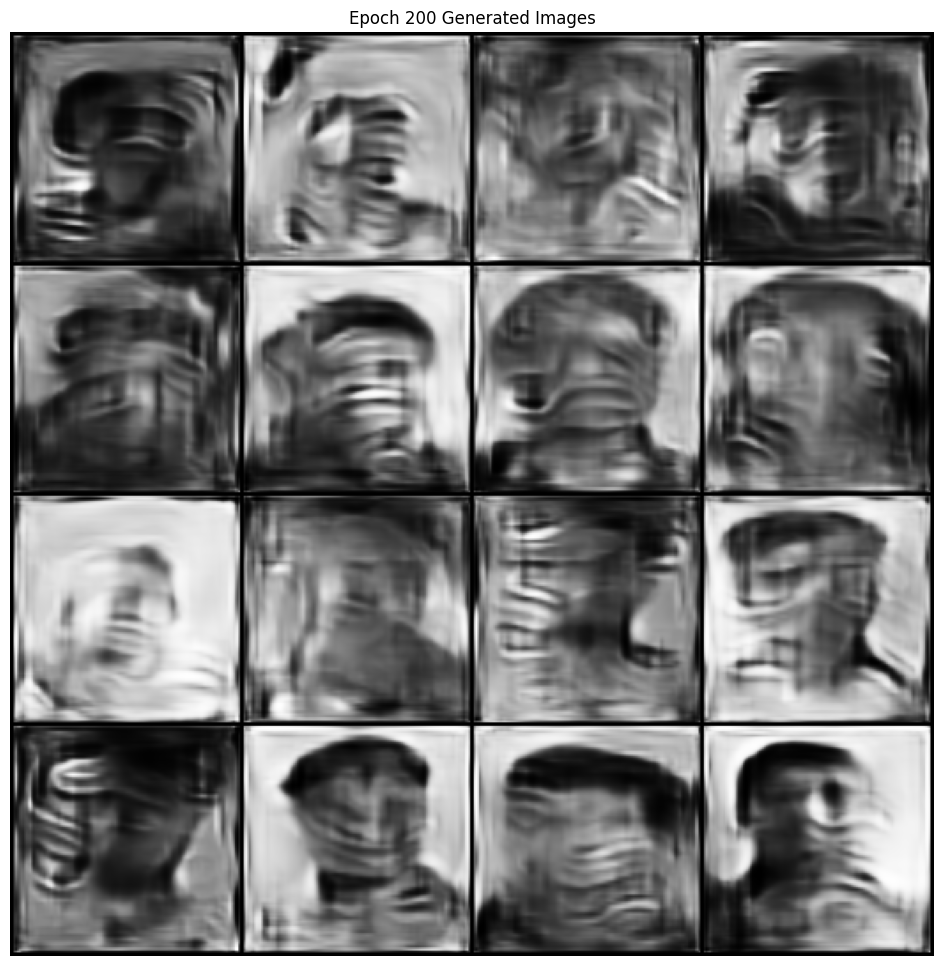

In [21]:
best_g_loss = float('inf')  # Track best generator loss

for epoch in range(start_epoch, num_epochs):
    d_epoch_loss = 0.0
    g_epoch_loss = 0.0

    for i, (real_images, _) in enumerate(train_loader):
        batch_size = real_images.size(0)
        real_images = real_images.to(device)

        # Label smoothing: real = 0.9, fake = 0.1
        real_labels = torch.full((batch_size, 1), 0.9, device=device)
        fake_labels = torch.full((batch_size, 1), 0.1, device=device)

        ### -------- Train Discriminator --------
        discriminator_optimizer.zero_grad()

        # Real
        real_outputs = discriminator(real_images)
        d_real_loss = criterion(real_outputs, real_labels)

        # Fake
        z = torch.randn(batch_size, latent_dim).to(device)
        fake_images = generator(z)
        fake_outputs = discriminator(fake_images.detach())
        d_fake_loss = criterion(fake_outputs, fake_labels)

        # Total Discriminator Loss
        d_loss = d_real_loss + d_fake_loss
        d_epoch_loss += d_loss.item()

        d_loss.backward()
        discriminator_optimizer.step()

        ### -------- Train Generator --------
        generator_optimizer.zero_grad()

        outputs = discriminator(fake_images)
        g_loss = criterion(outputs, real_labels)  # try to fool discriminator
        g_epoch_loss += g_loss.item()

        g_loss.backward()
        generator_optimizer.step()

        if (i + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{len(train_loader)}], "
                  f"D Loss: {d_loss.item():.4f}, G Loss: {g_loss.item():.4f}, "
                  f"D(x): {real_outputs.mean().item():.2f}, D(G(z)): {fake_outputs.mean().item():.2f}")

    # Average losses
    avg_g_loss = g_epoch_loss / len(train_loader)
    avg_d_loss = d_epoch_loss / len(train_loader)
    gen_losses.append(avg_g_loss)
    disc_losses.append(avg_d_loss)

    ### -------- Save best model every 5 epochs --------
    if (epoch + 1) % 10 == 0:
        # if avg_g_loss < best_g_loss:
        best_g_loss = avg_g_loss
        torch.save(generator.state_dict(), os.path.join(checkpoint_dir, f"best_generator_epoch{epoch+1}.pth"))
        torch.save(discriminator.state_dict(), os.path.join(checkpoint_dir, f"best_discriminator_epoch{epoch+1}.pth"))
        print(f"Best model saved at epoch {epoch+1} (G Loss: {best_g_loss:.4f})")

    ### -------- Visualization every 10 epochs --------
    if (epoch + 1) % 10 == 0:
        with torch.no_grad():
            z_vis = torch.randn(16, latent_dim).to(device)
            gen_imgs = generator(z_vis).cpu()
            grid = make_grid(gen_imgs, nrow=4, normalize=True, scale_each=True)
            plt.figure(figsize=(12, 12))
            plt.imshow(grid.permute(1, 2, 0).numpy(), cmap='gray')
            plt.axis('off')
            plt.title(f"Epoch {epoch+1} Generated Images")
            plt.show()

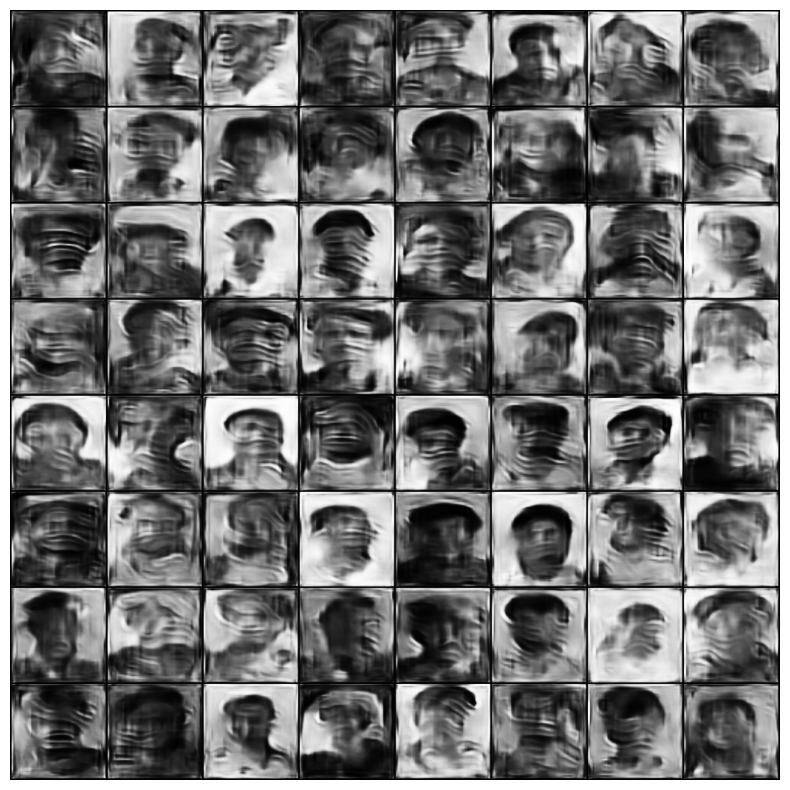

In [22]:
generator.eval()

with torch.no_grad():
    noise = torch.randn(64, latent_dim).to(device)
    fake_images = generator(noise)
    fake_images = (fake_images + 1) / 2  # Rescale to [0, 1]
    grid = make_grid(fake_images, nrow=8, normalize=True)
    save_image(grid, "generated_images_final.png")

# Display the generated images
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(np.transpose(grid.cpu().numpy(), (1, 2, 0)))
ax.axis('off')
plt.show()


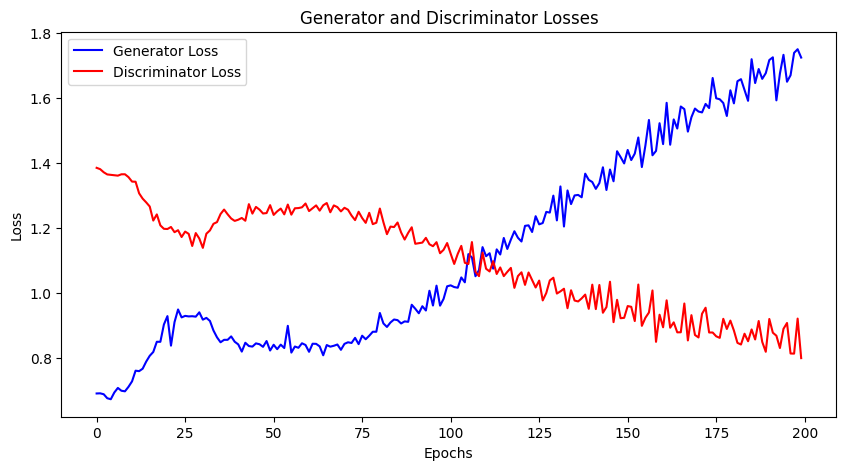

In [23]:
#Display the losses
plt.figure(figsize=(10, 5))
plt.plot(gen_losses, label='Generator Loss', color='blue')
plt.plot(disc_losses, label='Discriminator Loss', color='red')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Generator and Discriminator Losses')
plt.legend()
plt.show()

In [24]:
# Save the final models
torch.save(generator.state_dict(), generator_checkpoint_path)
torch.save(discriminator.state_dict(), discriminator_checkpoint_path)

In [25]:
# save losses to a file
import json
losses = {
    'generator_losses': gen_losses,
    'discriminator_losses': disc_losses
}
with open('losses.json', 'w') as f:
    json.dump(losses, f)

In [26]:
checkpoint_dir = "checkpoints"
generator_checkpoint_path = os.path.join(checkpoint_dir, "generator.pth")
discriminator_checkpoint_path = os.path.join(checkpoint_dir, "discriminator.pth")

In [ ]:
def generate_random_image(generator, latent_dim=100):
    noise = torch.randn(1, latent_dim).to(device)
    with torch.no_grad():
        generated_image = generator(noise)
    return generated_image

# Function to calculate similarity between two images
def calculate_similarity(image1, image2):
    # Flatten the images and calculate cosine similarity
    image1_flat = image1.view(-1)
    image2_flat = image2.view(-1)
    similarity = torch.nn.functional.cosine_similarity(image1_flat, image2_flat, dim=0)
    return similarity.item()

original_image, _ = next(iter(train_loader))
original_image = original_image[0].to(device) 
generated_image = generate_random_image(generator)  
similarity = calculate_similarity(original_image, generated_image.squeeze())
print(f"Similarity between original and generated image: {similarity:.4f}")



Similarity between original and generated image: 0.1325
